# General Exploration — Greenlight Experiment

In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))
import paths

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

FOLDER_NAME = "20260527_000623_scenario_elia_midterm"
run_folder = paths.MULTI_RUN_OUTPUT / FOLDER_NAME

df = pd.read_csv(run_folder / "results.csv")
print(f"Loaded {len(df)} runs  |  {df['scenario'].nunique()} scenarios  |  {df['policy'].nunique()} policies")

Loaded 900 runs  |  100 scenarios  |  18 policies


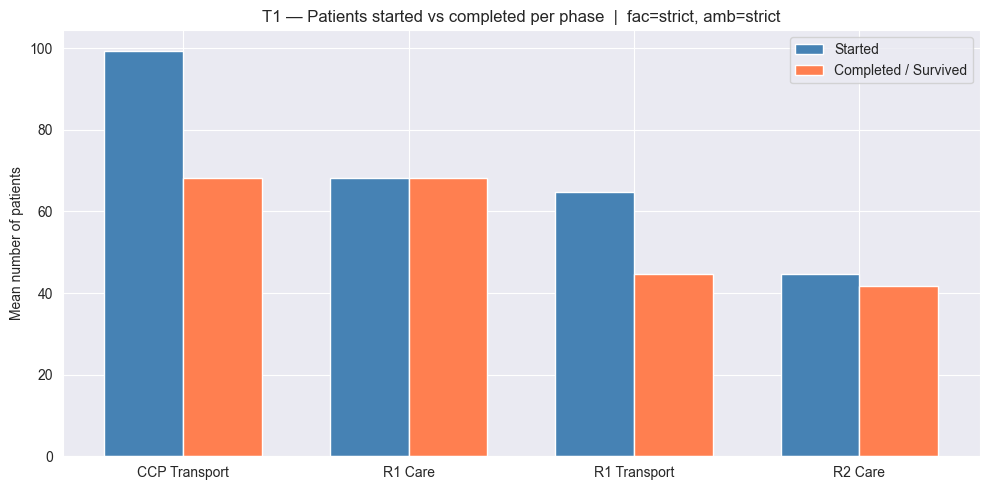

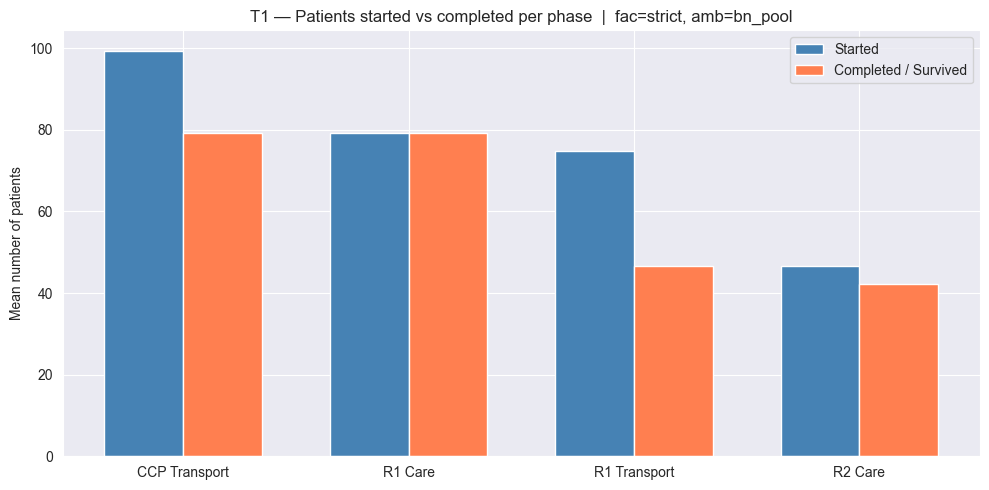

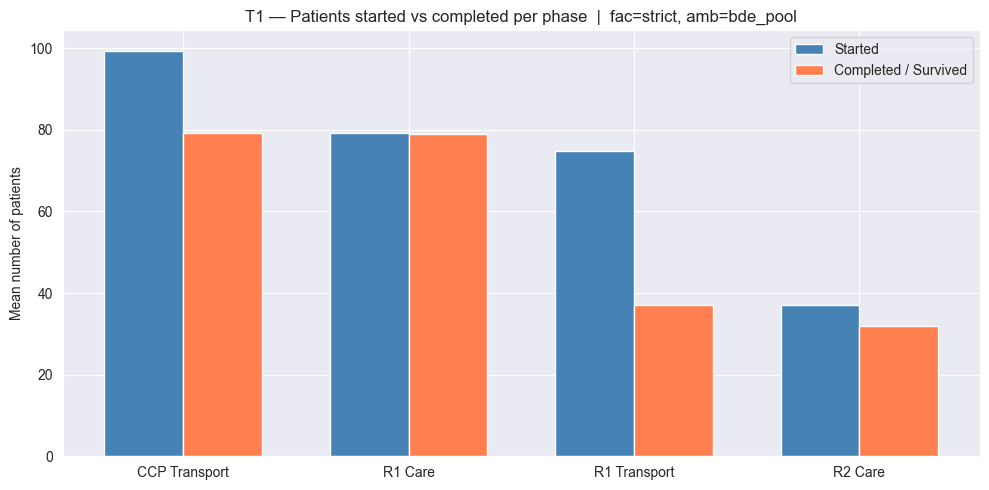

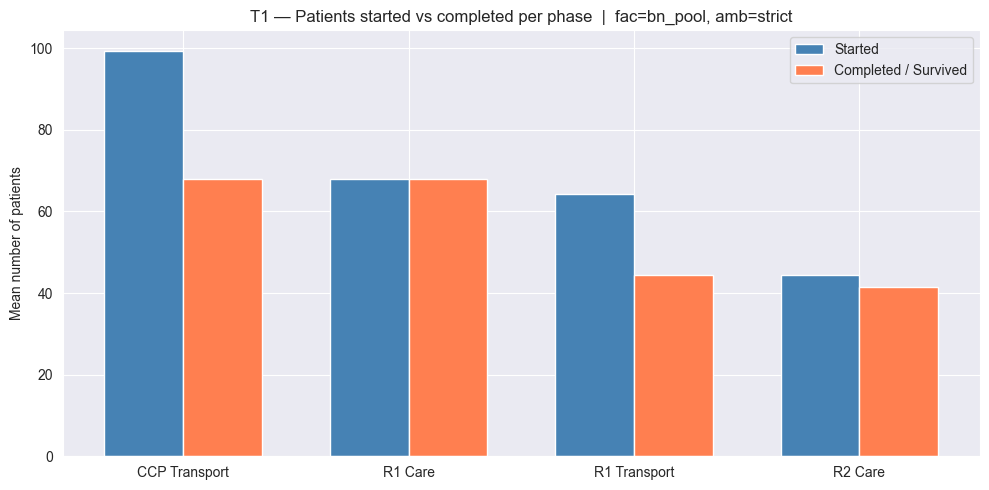

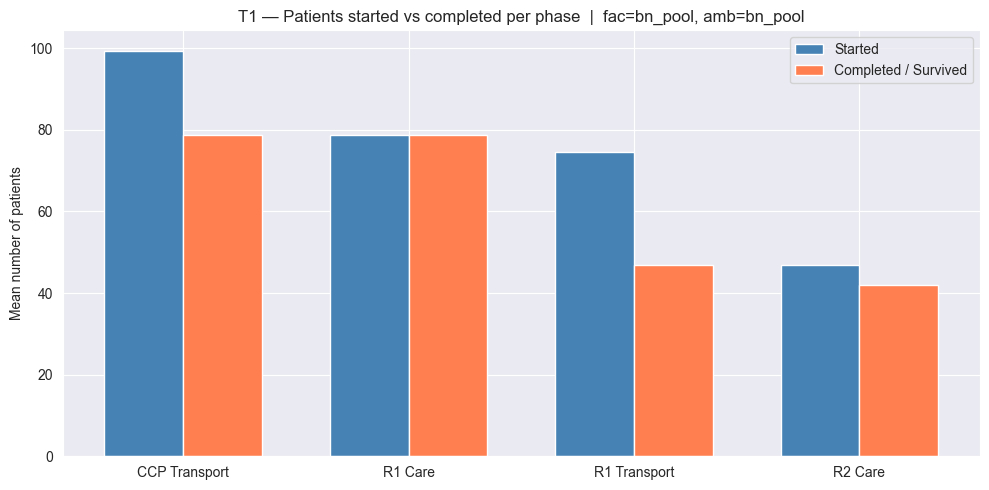

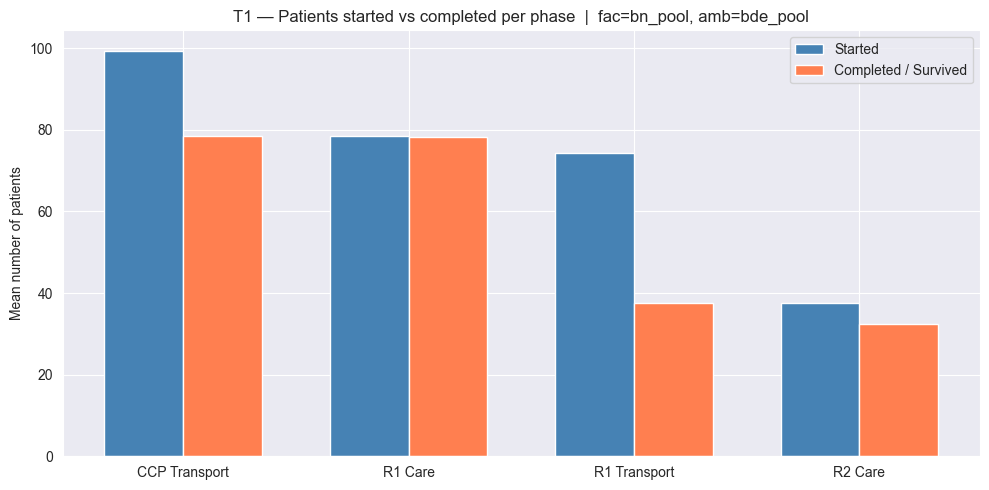

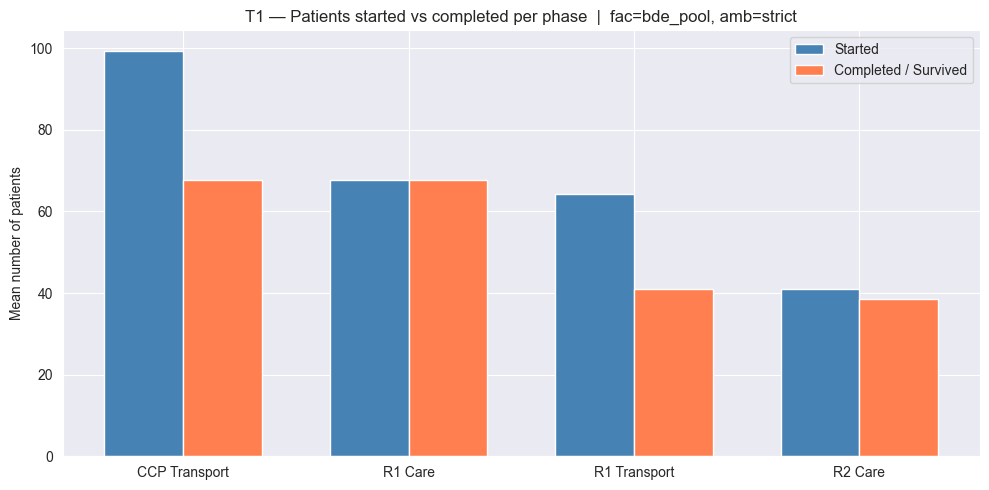

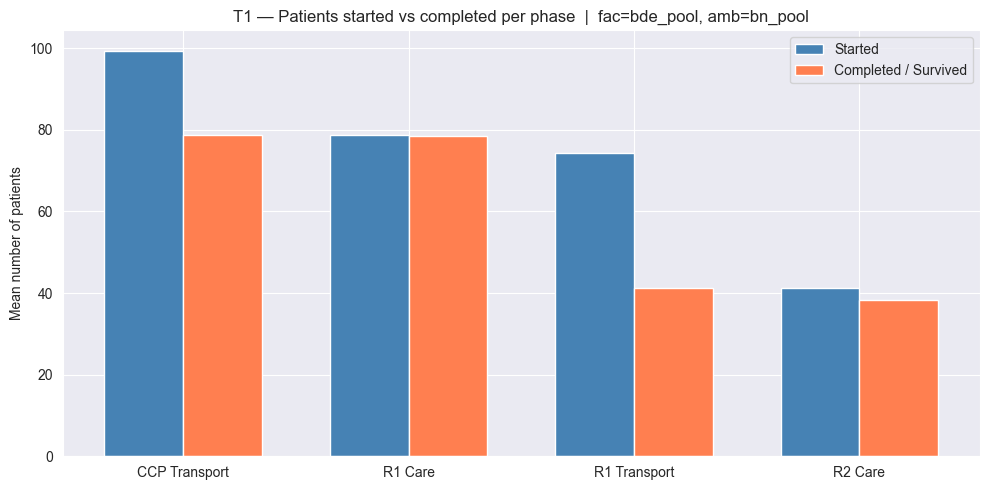

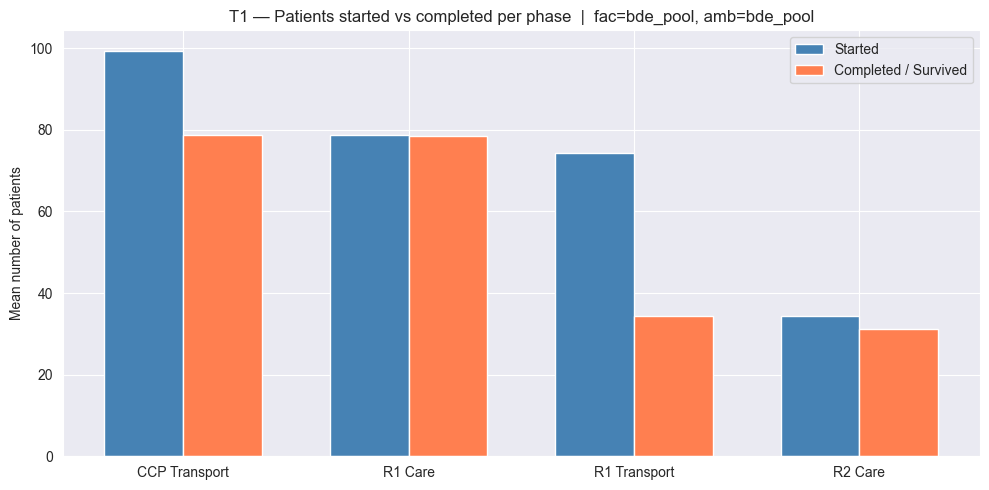

In [11]:
phases = ["ccp_transport", "r1_care", "r1_transport", "r2_care"]
phase_labels = ["CCP Transport", "R1 Care", "R1 Transport", "R2 Care"]
POLICY_LABELS = {0: "strict", 1: "bn_pool", 2: "bde_pool"}

x = np.arange(len(phases))
w = 0.35

for fe in sorted(df["facility_eligibility"].unique()):
    for ae in sorted(df["ambulance_eligibility"].unique()):
        plabel = f"fac={POLICY_LABELS[fe]}, amb={POLICY_LABELS[ae]}"
        pol = df[(df["facility_eligibility"] == fe) & (df["ambulance_eligibility"] == ae)]

        started = [pol[f"n_started_{p}_T1"].mean() for p in phases]
        completed = []
        for p in phases:
            col = f"n_completed_{p}_T1"
            if col in pol.columns:
                completed.append(pol[col].mean())
            elif f"n_safe_{p}_T1" in pol.columns:
                completed.append(pol[f"n_safe_{p}_T1"].mean())
            else:
                completed.append((pol[f"n_started_{p}_T1"] * (1 - pol[f"mortality_{p}_T1"])).mean())

        fig, ax = plt.subplots(figsize=(10, 5))
        ax.bar(x - w/2, started, w, label="Started", color="steelblue")
        ax.bar(x + w/2, completed, w, label="Completed / Survived", color="coral")
        ax.set_xticks(x)
        ax.set_xticklabels(phase_labels)
        ax.set_ylabel("Mean number of patients")
        ax.set_title(f"T1 — Patients started vs completed per phase  |  {plabel}")
        ax.legend()
        plt.tight_layout()
        plt.show()

In [ ]:
for fe in sorted(df["facility_eligibility"].unique()):
    for ae in sorted(df["ambulance_eligibility"].unique()):
        plabel = f"fac={POLICY_LABELS[fe]}, amb={POLICY_LABELS[ae]}"
        pol = df[(df["facility_eligibility"] == fe) & (df["ambulance_eligibility"] == ae)]

        started = [pol[f"n_started_{p}_T2"].mean() for p in phases]
        completed = []
        for p in phases:
            col = f"n_completed_{p}_T2"
            if col in pol.columns:
                completed.append(pol[col].mean())
            elif f"n_safe_{p}_T2" in pol.columns:
                completed.append(pol[f"n_safe_{p}_T2"].mean())
            else:
                completed.append((pol[f"n_started_{p}_T2"] * (1 - pol[f"mortality_{p}_T2"])).mean())

        fig, ax = plt.subplots(figsize=(10, 5))
        ax.bar(x - w/2, started, w, label="Started", color="steelblue")
        ax.bar(x + w/2, completed, w, label="Completed / Survived", color="coral")
        ax.set_xticks(x)
        ax.set_xticklabels(phase_labels)
        ax.set_ylabel("Mean number of patients")
        ax.set_title(f"T2 — Patients started vs completed per phase  |  {plabel}")
        ax.legend()
        plt.tight_layout()
        plt.show()

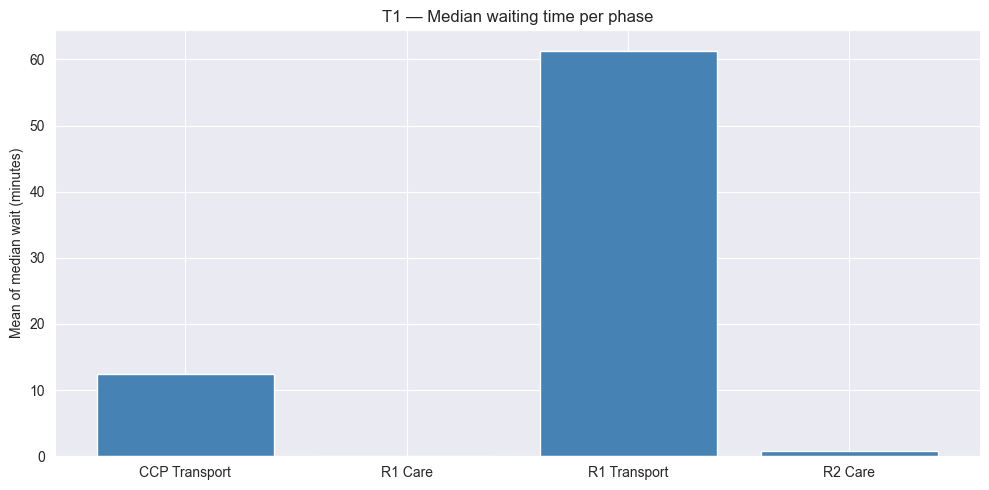

In [4]:
wait_cols = [f"median_wait_{p}_T1" for p in phases]
waits = [df[c].mean() for c in wait_cols]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(phase_labels, waits, color="steelblue")
ax.set_ylabel("Mean of median wait (minutes)")
ax.set_title("T1 — Median waiting time per phase")
plt.tight_layout()
plt.show()

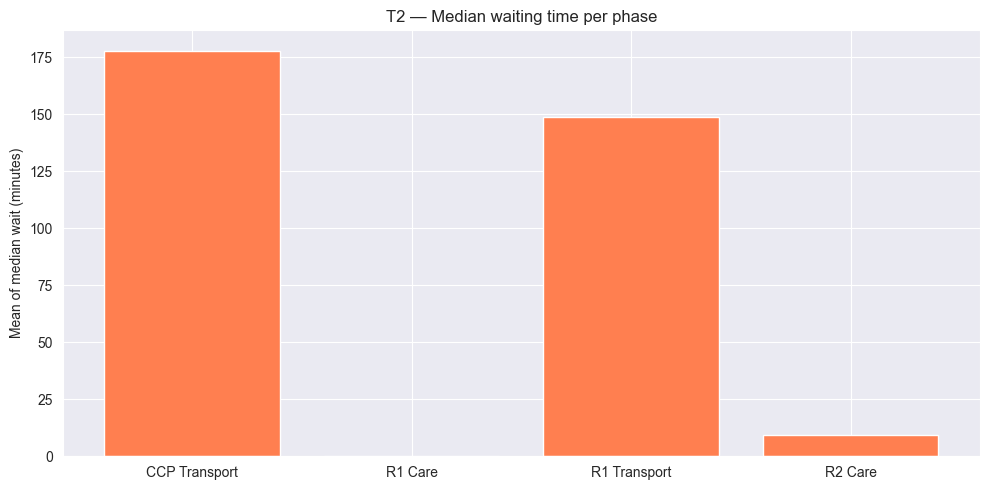

In [5]:
wait_cols = [f"median_wait_{p}_T2" for p in phases]
waits = [df[c].mean() for c in wait_cols]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(phase_labels, waits, color="coral")
ax.set_ylabel("Mean of median wait (minutes)")
ax.set_title("T2 — Median waiting time per phase")
plt.tight_layout()
plt.show()

In [6]:
POLICY_LABELS = {0: "strict", 1: "bn_pool", 2: "bde_pool"}
POLICIES = [
    (fe, ae)
    for fe in [0, 1, 2]
    for ae in [0, 1, 2]
    if not (fe == 0 and ae == 0)
]
strict = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 0)]

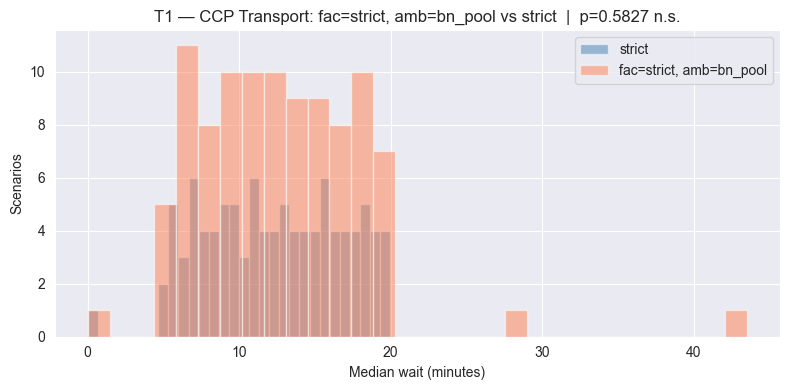

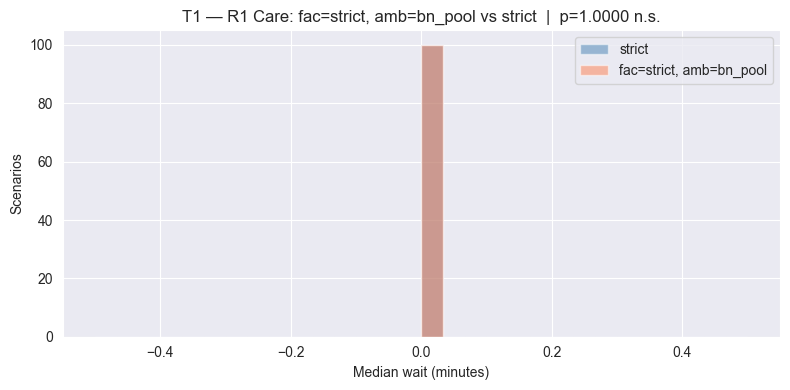

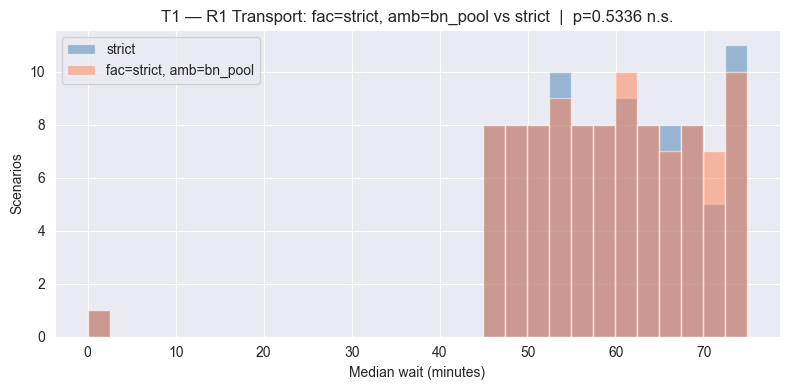

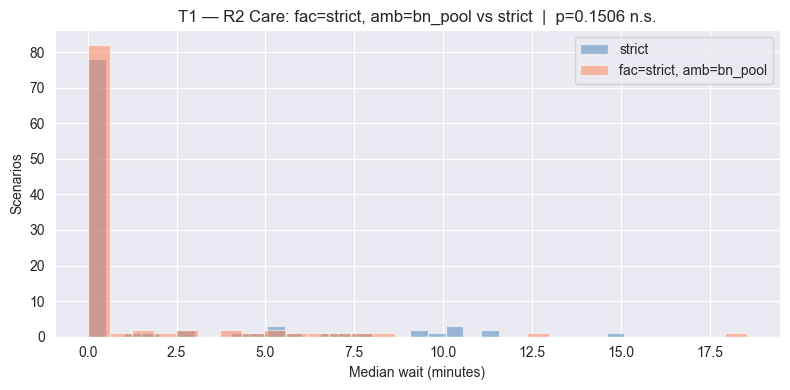

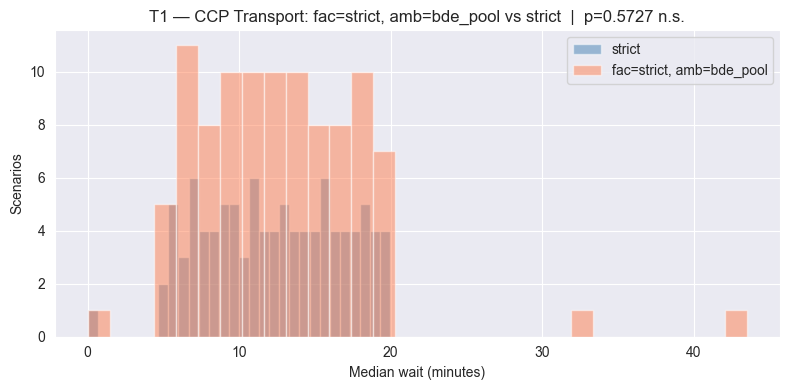

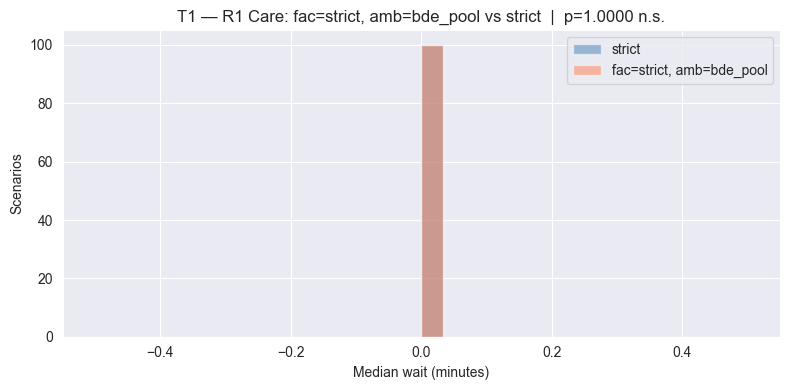

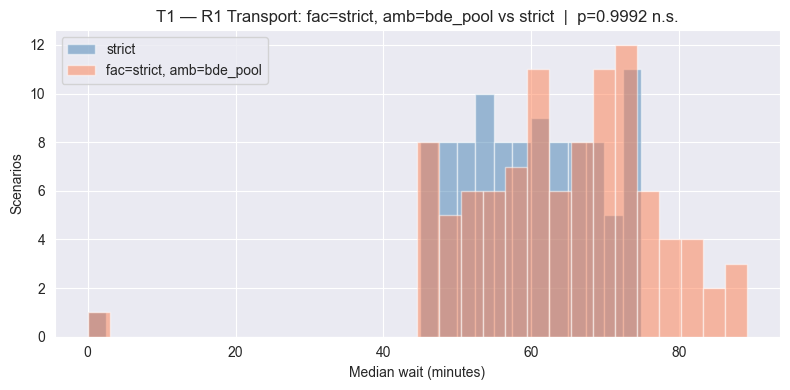

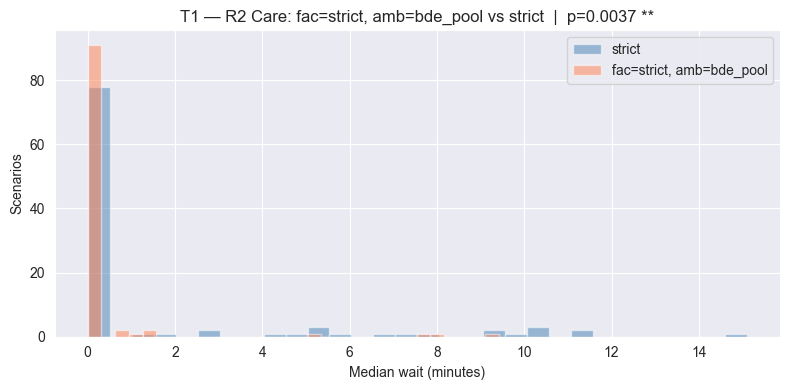

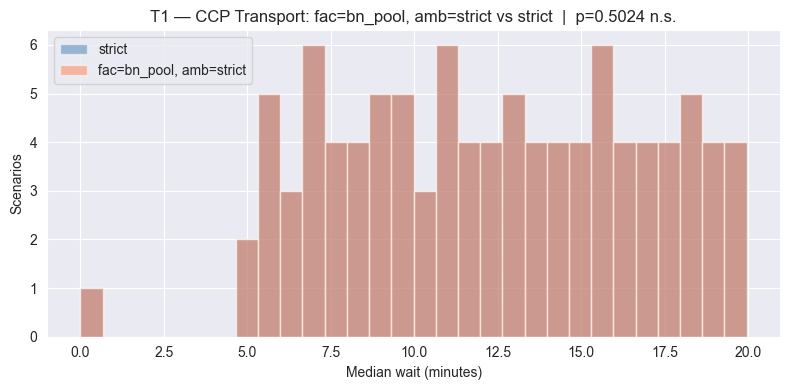

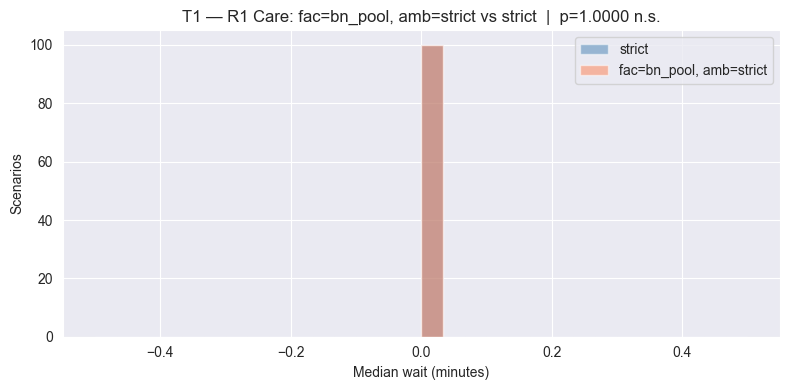

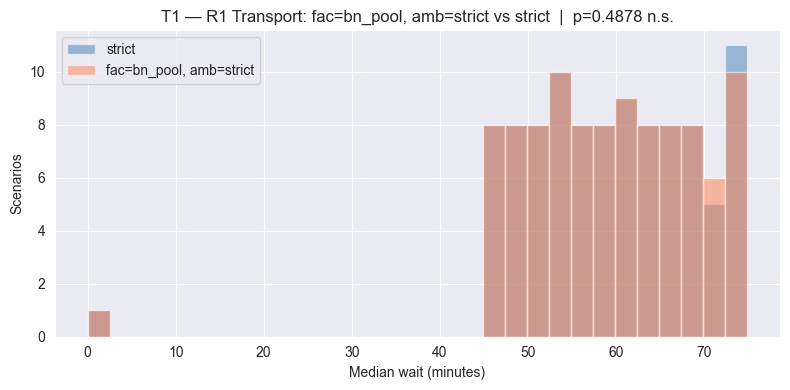

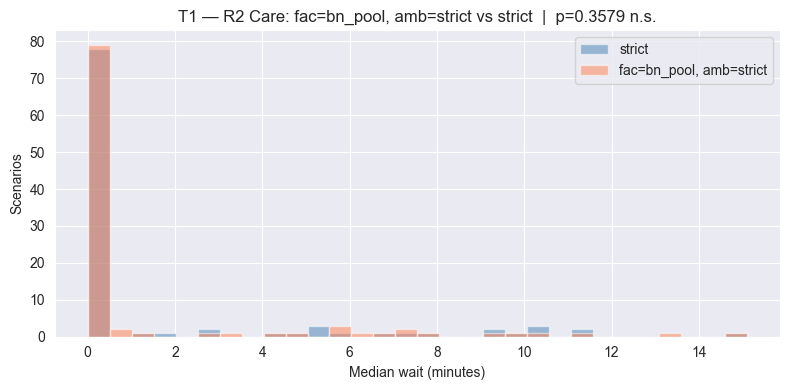

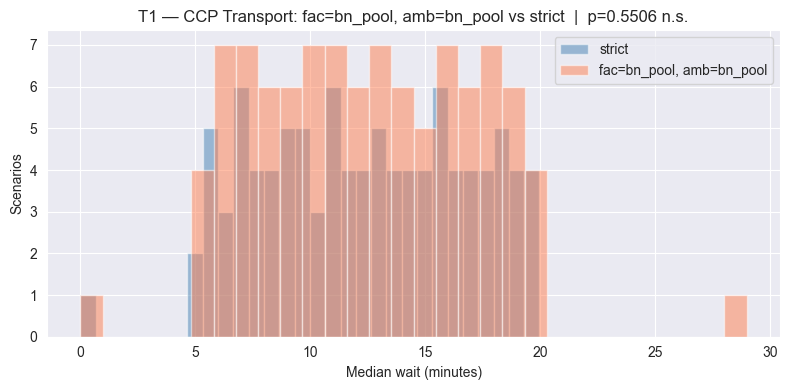

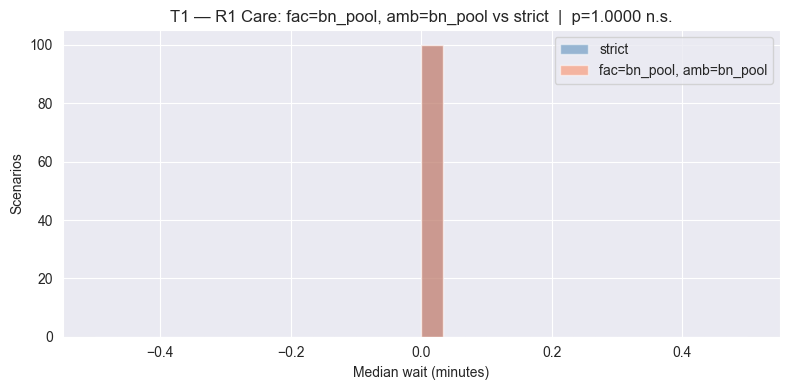

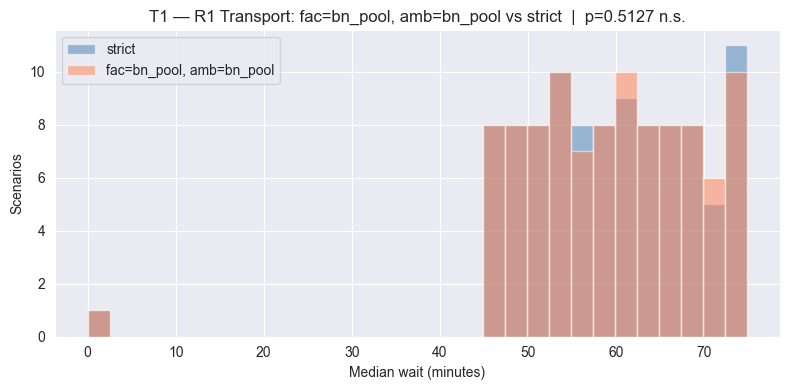

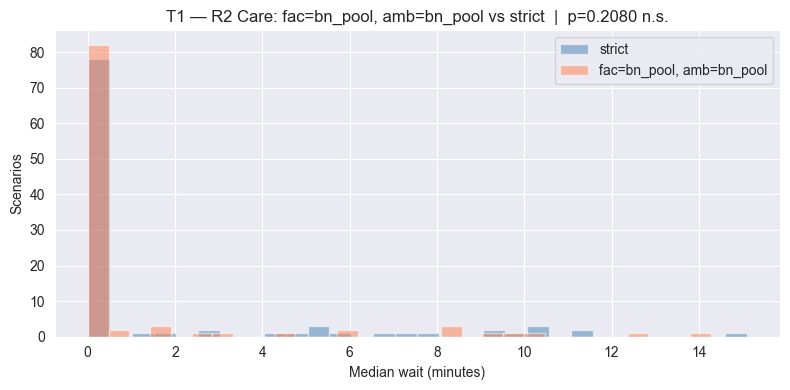

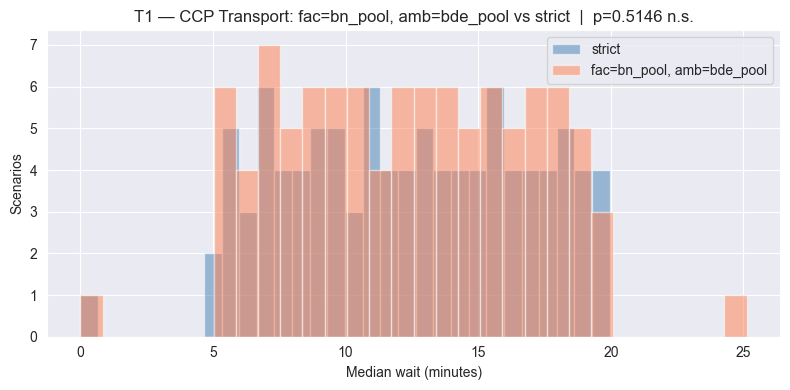

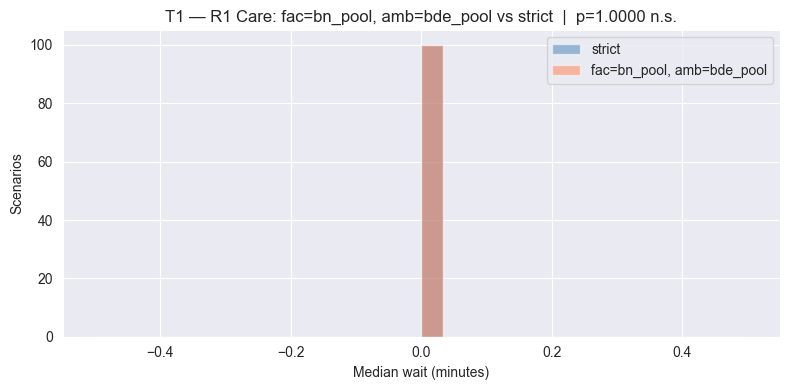

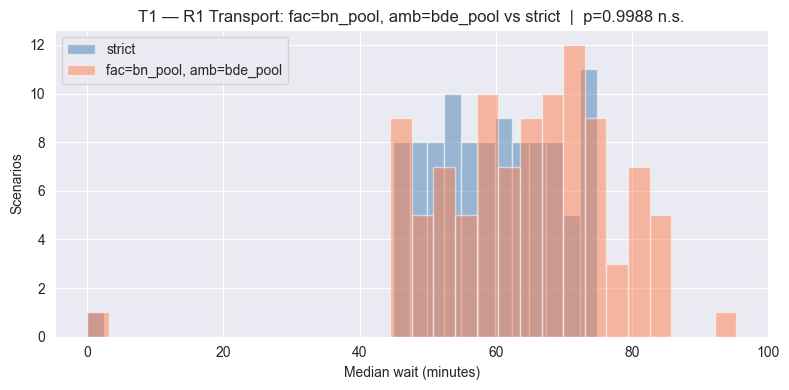

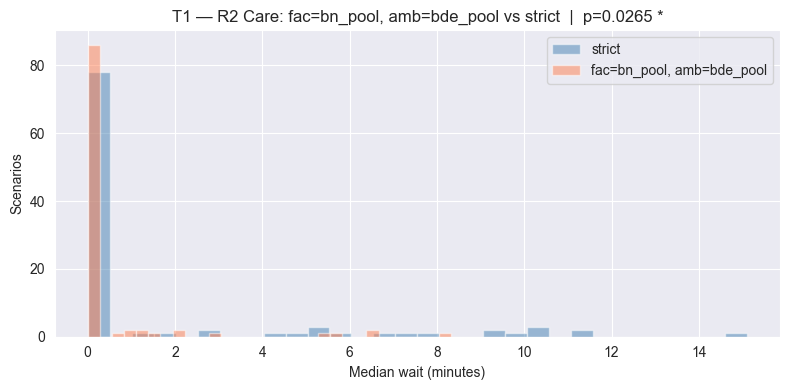

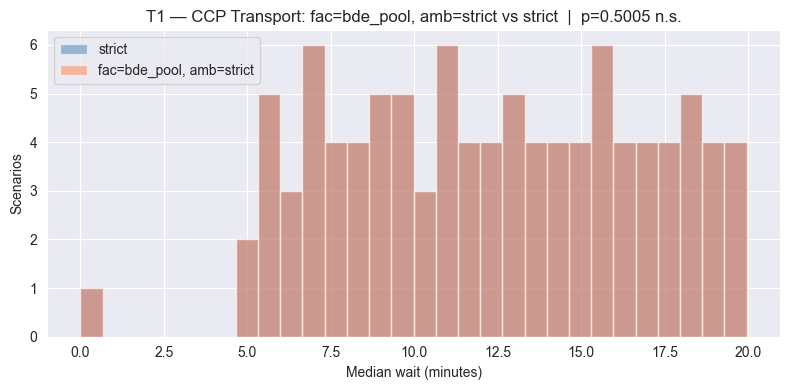

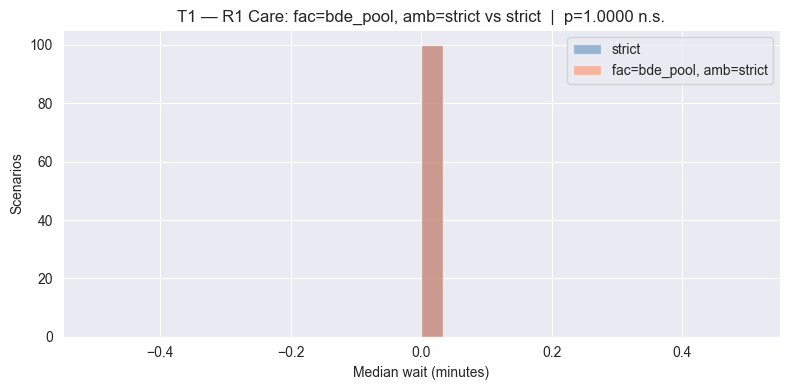

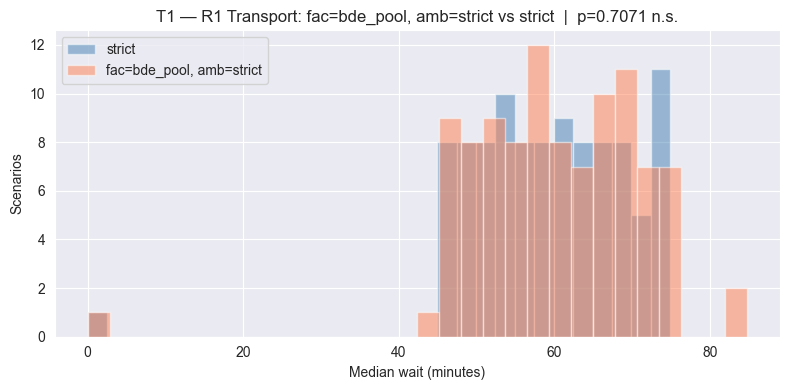

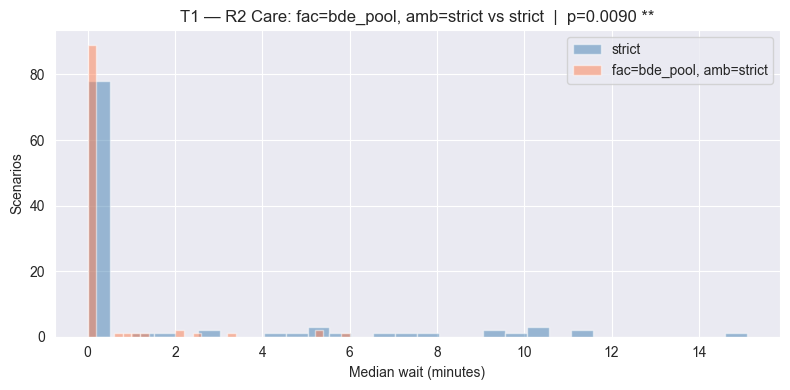

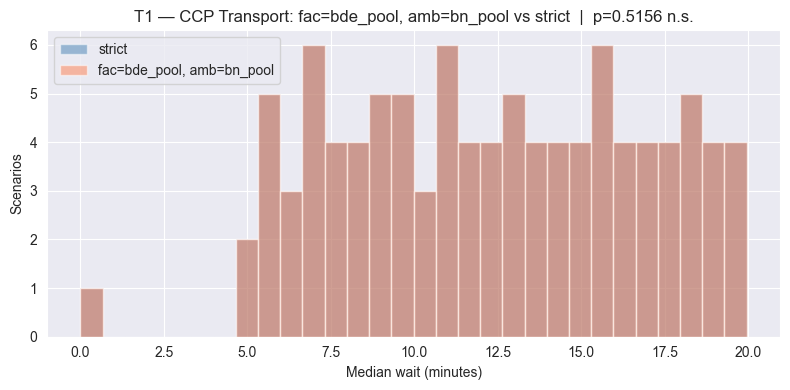

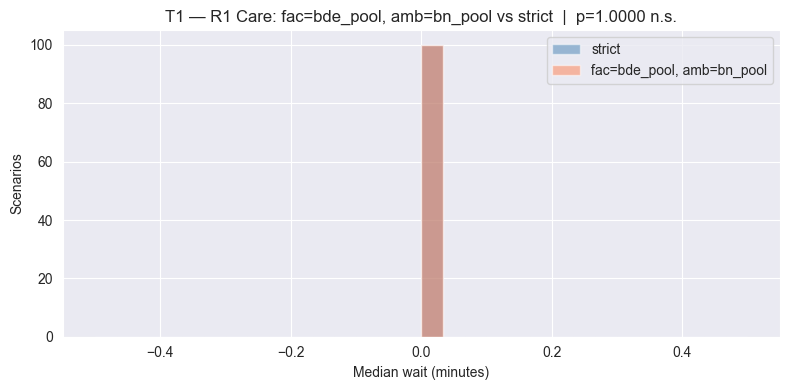

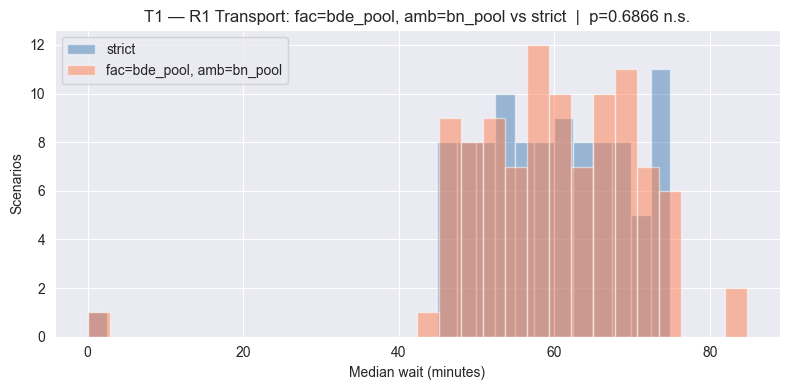

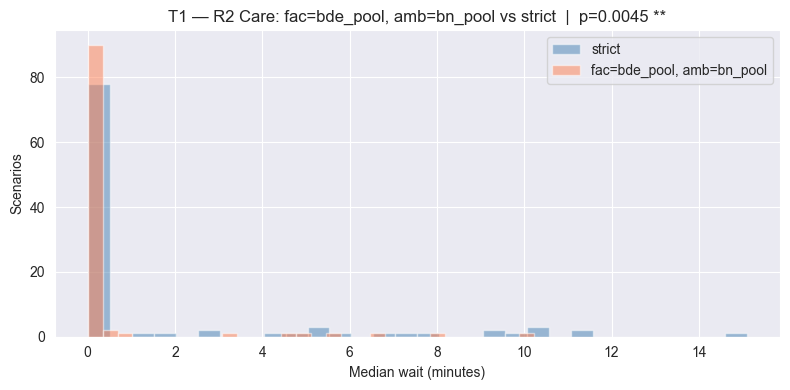

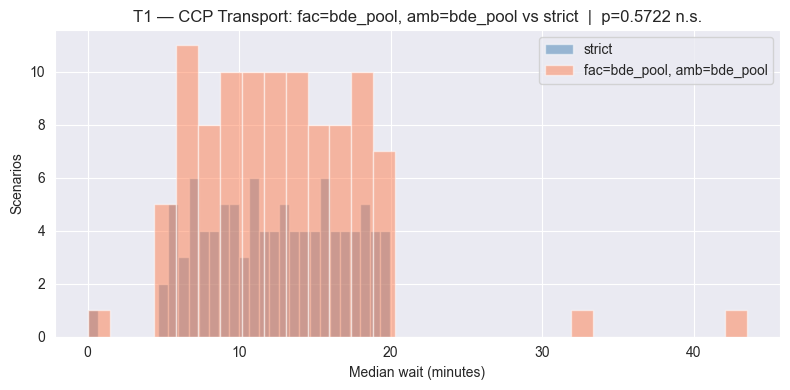

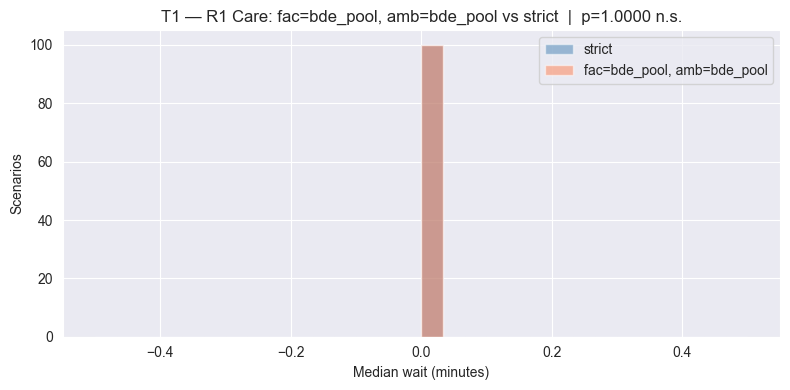

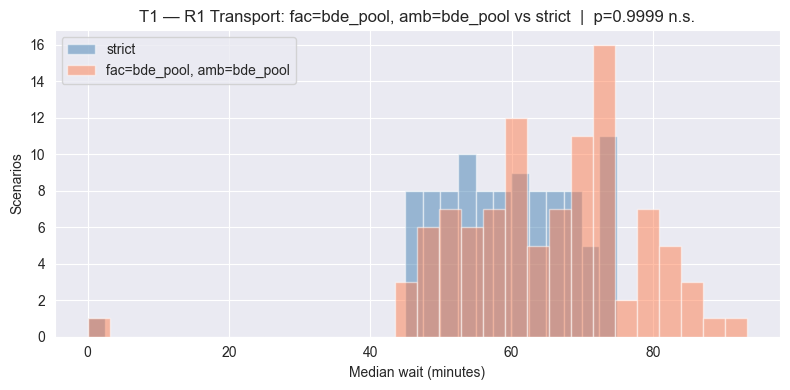

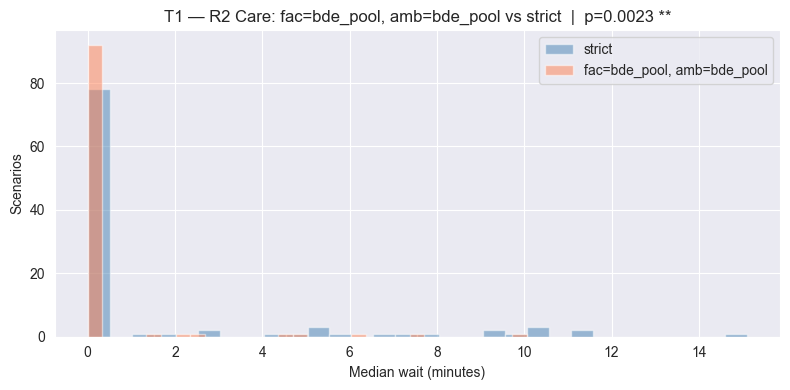

In [7]:
from scipy import stats

for fe, ae in POLICIES:
    plabel = f"fac={POLICY_LABELS[fe]}, amb={POLICY_LABELS[ae]}"
    pol = df[(df["facility_eligibility"] == fe) & (df["ambulance_eligibility"] == ae)]
    for p, phlabel in zip(phases, phase_labels):
        col = f"median_wait_{p}_T1"
        s = strict[col].dropna()
        q = pol[col].dropna()
        t, pval = stats.mannwhitneyu(s, q, alternative="greater")

        fig, ax = plt.subplots(figsize=(8, 4))
        ax.hist(s, bins=30, alpha=0.5, label="strict", color="steelblue")
        ax.hist(q, bins=30, alpha=0.5, label=plabel, color="coral")
        ax.set_xlabel("Median wait (minutes)")
        ax.set_ylabel("Scenarios")
        sig = "***" if pval < 0.001 else "**" if pval < 0.01 else "*" if pval < 0.05 else "n.s."
        ax.set_title(f"T1 — {phlabel}: {plabel} vs strict  |  p={pval:.4f} {sig}")
        ax.legend()
        plt.tight_layout()
        plt.show()

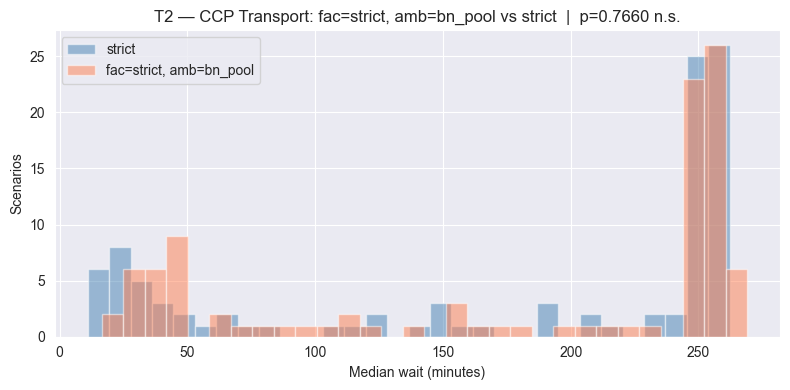

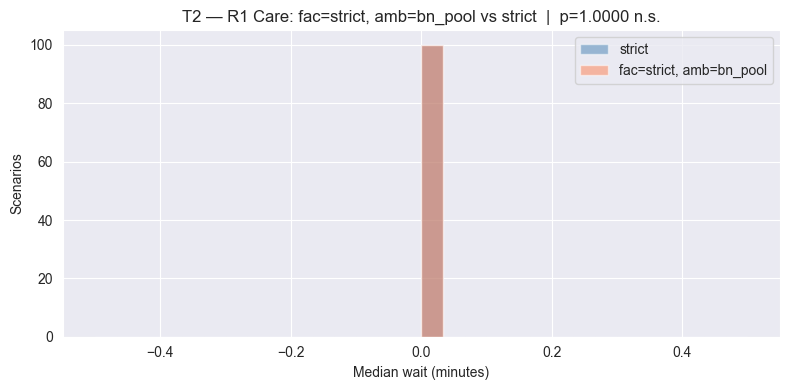

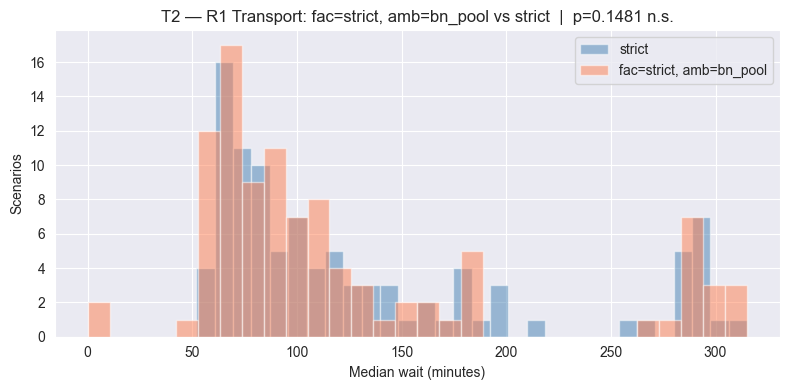

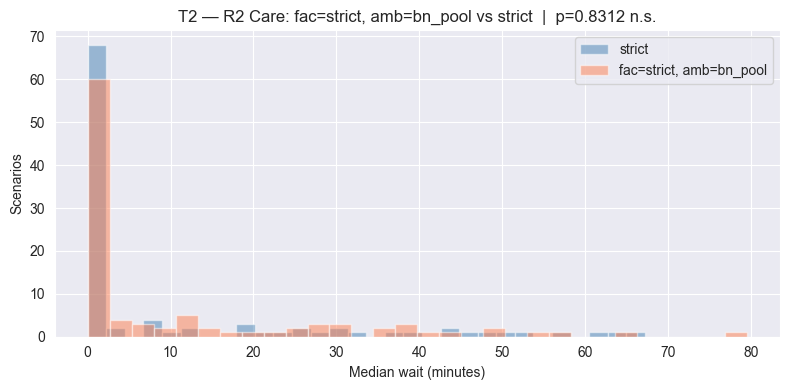

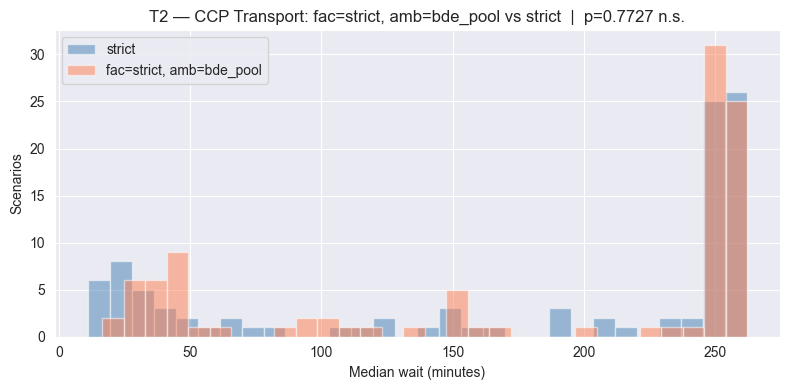

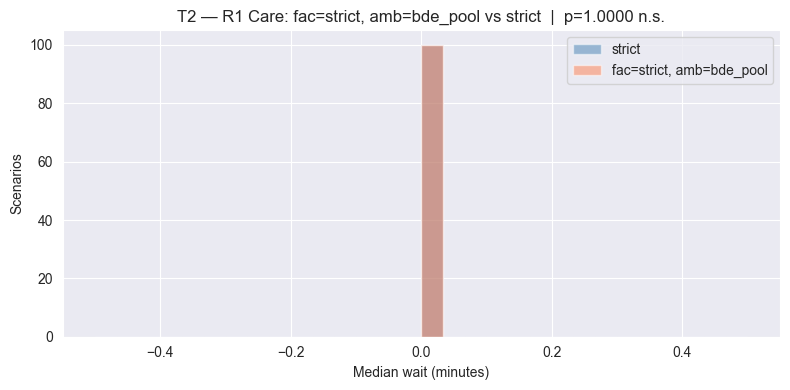

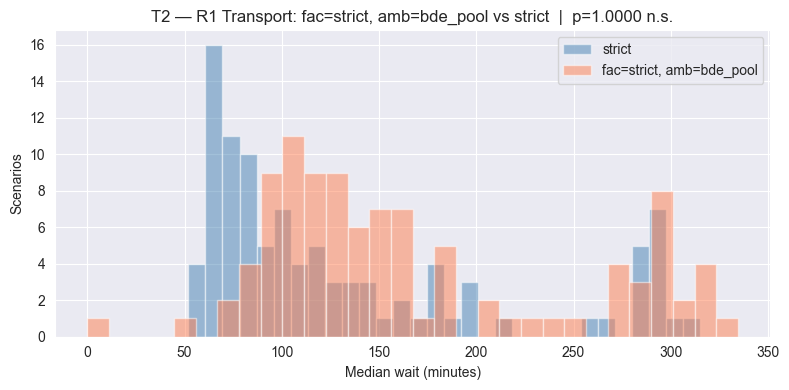

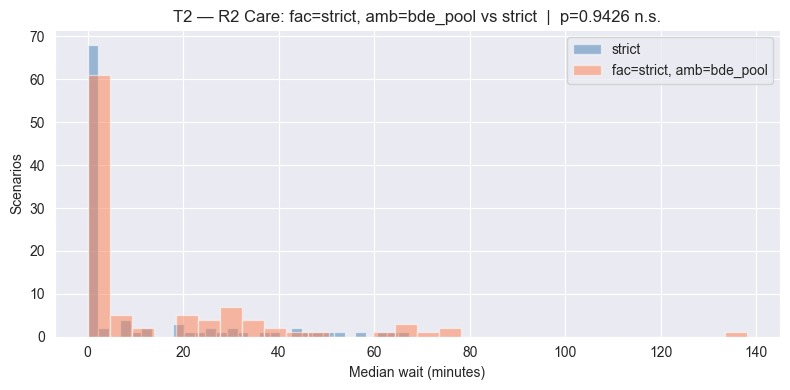

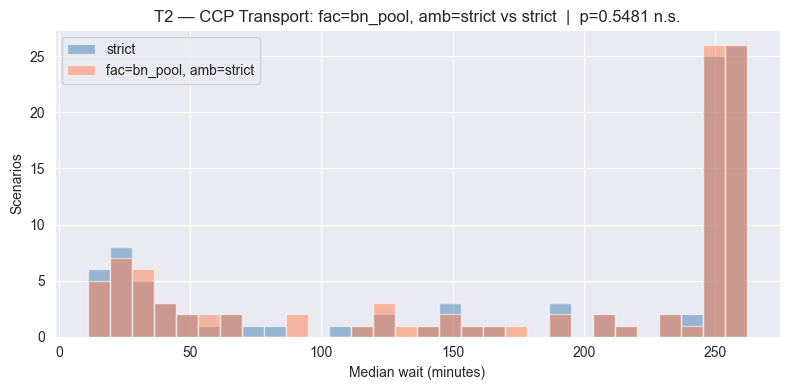

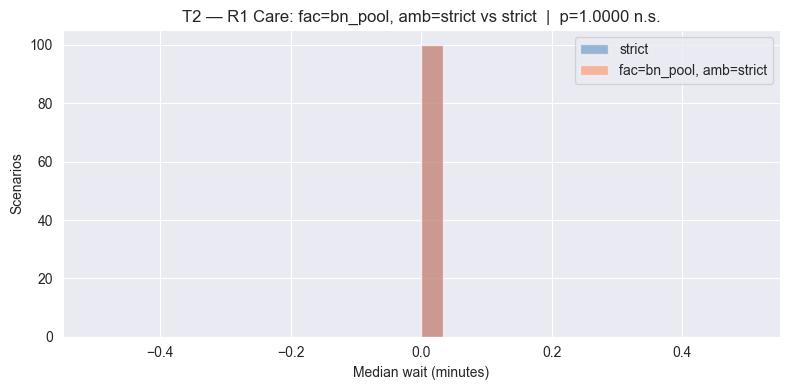

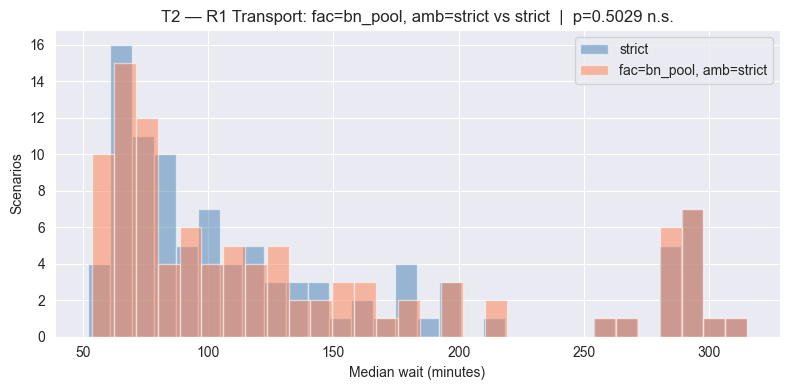

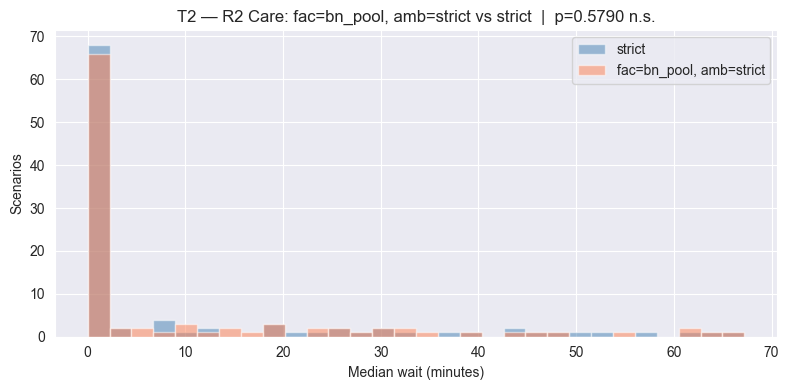

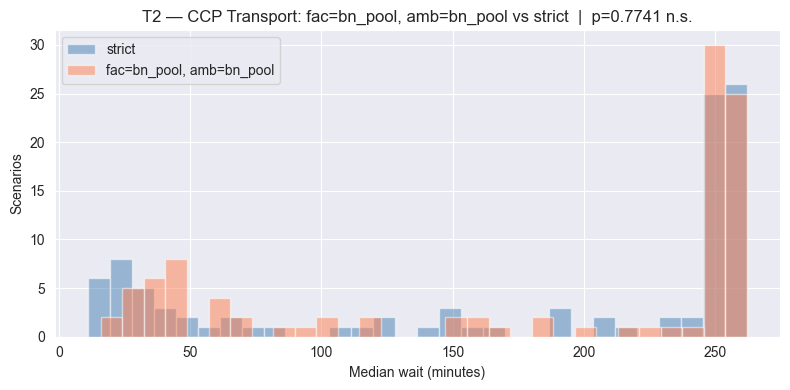

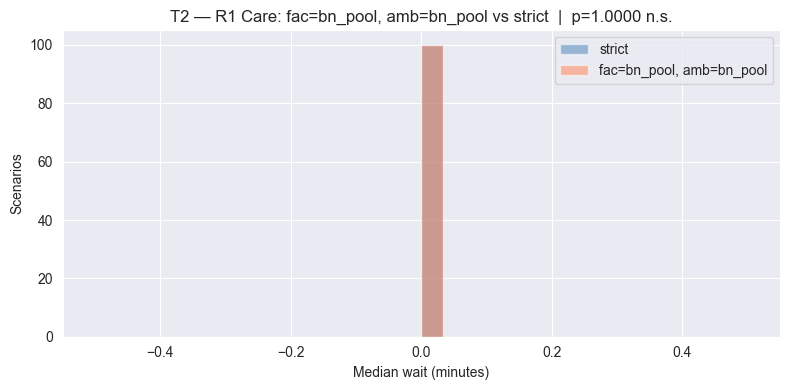

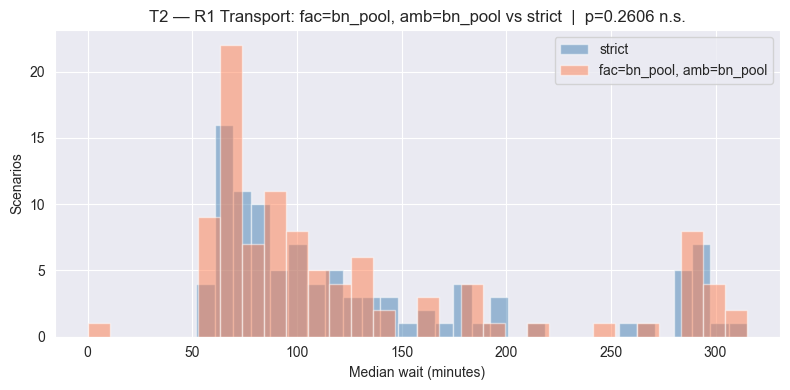

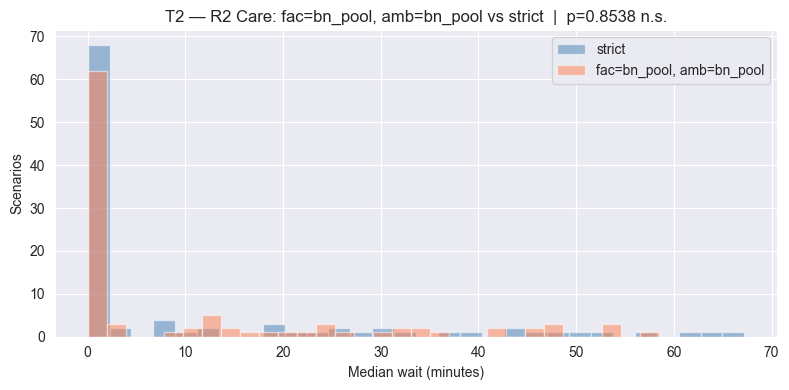

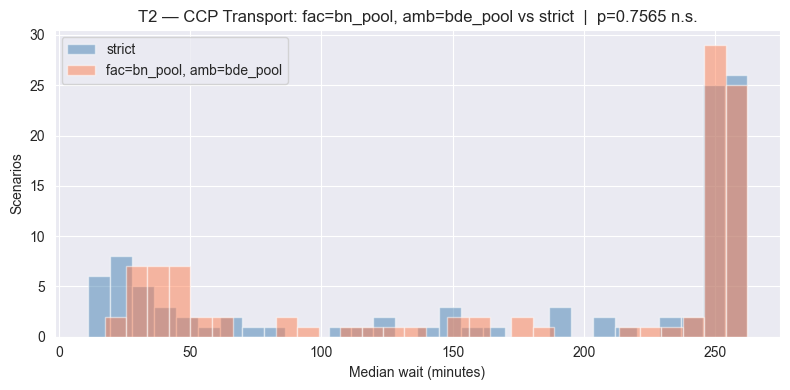

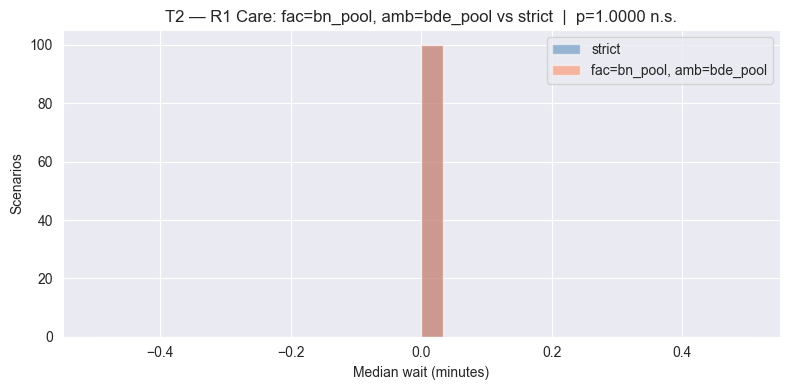

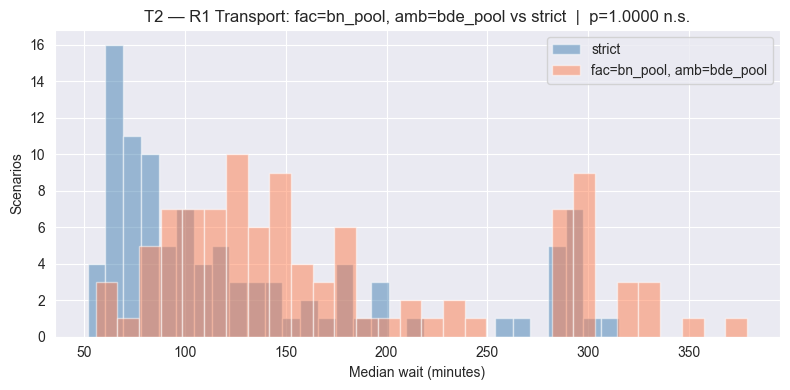

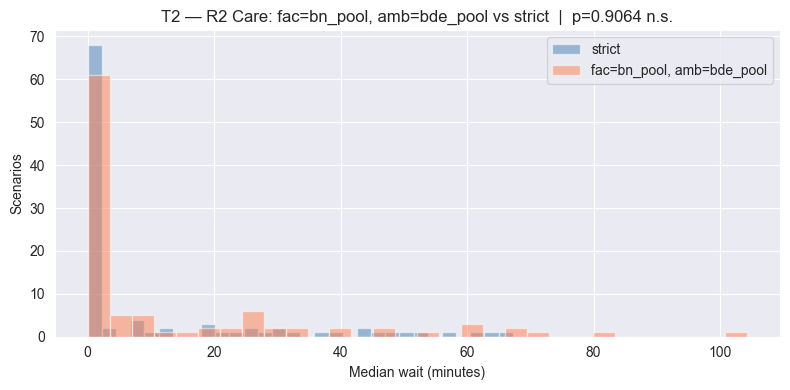

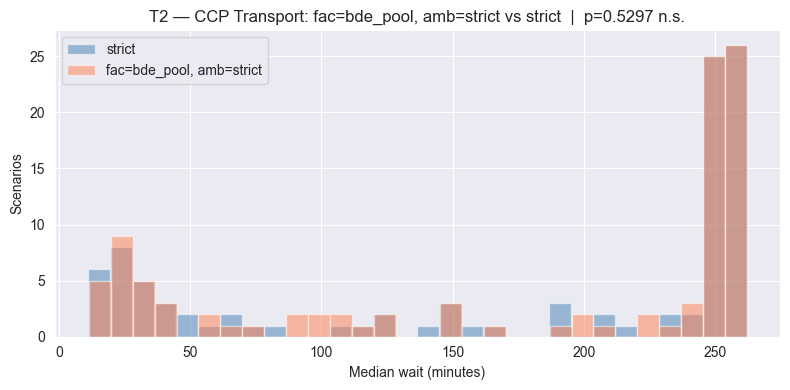

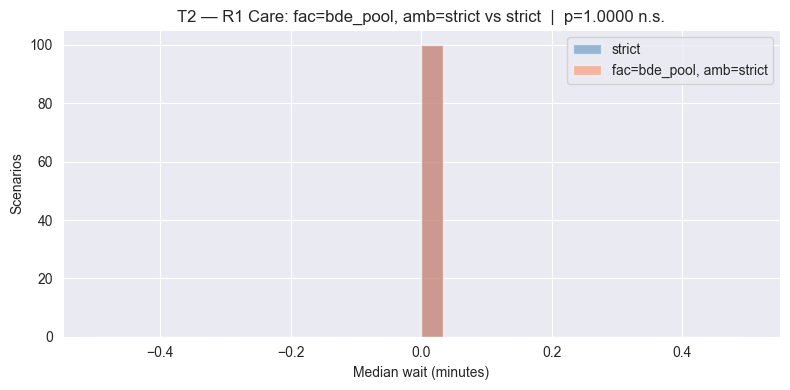

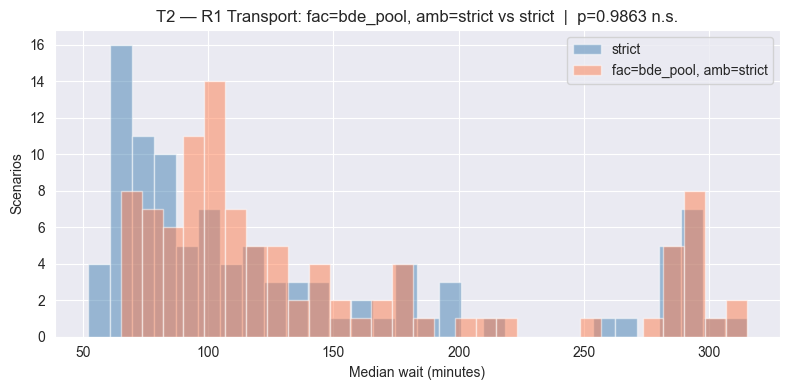

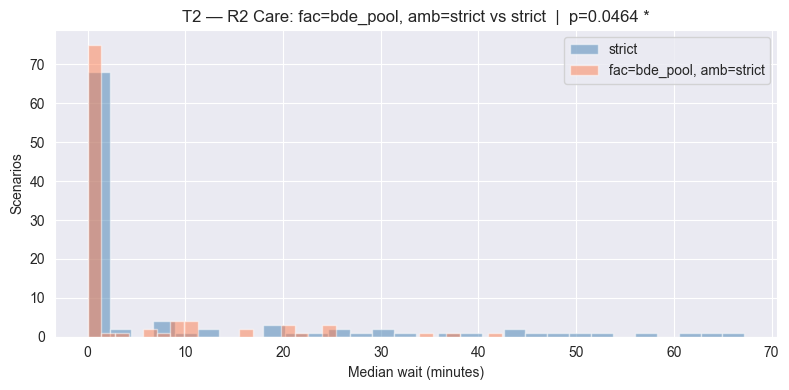

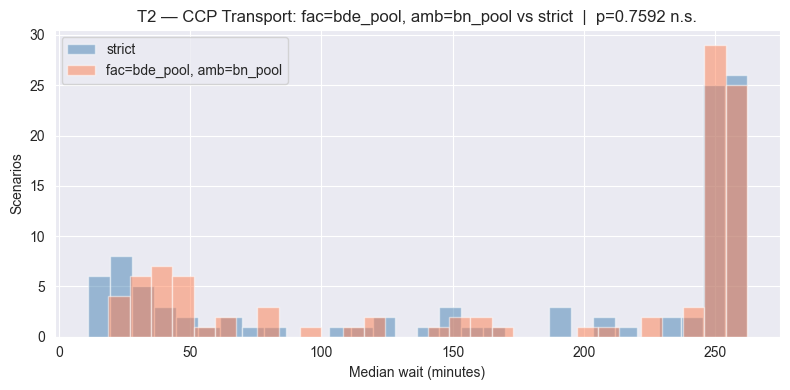

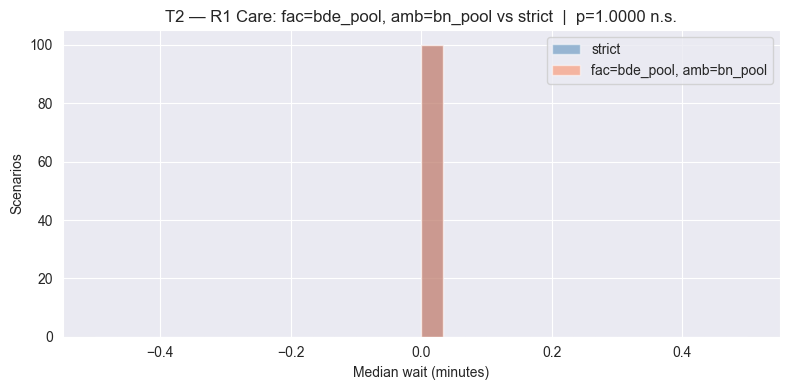

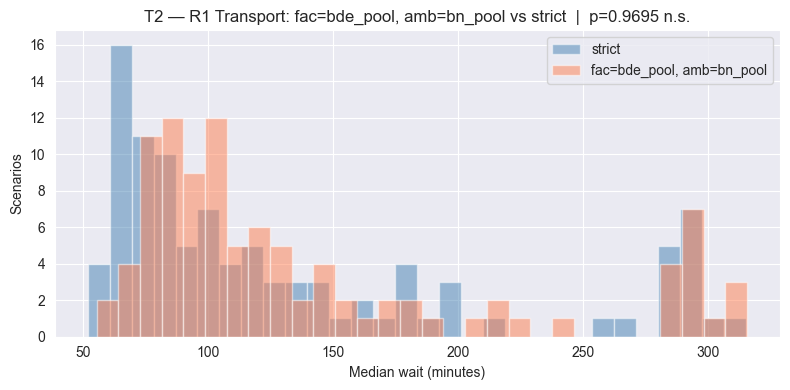

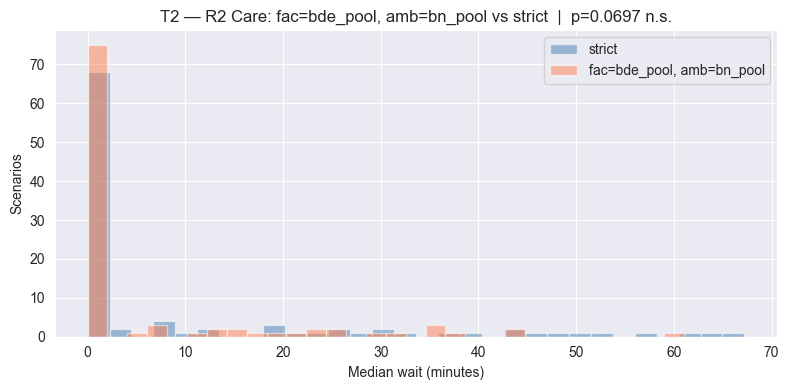

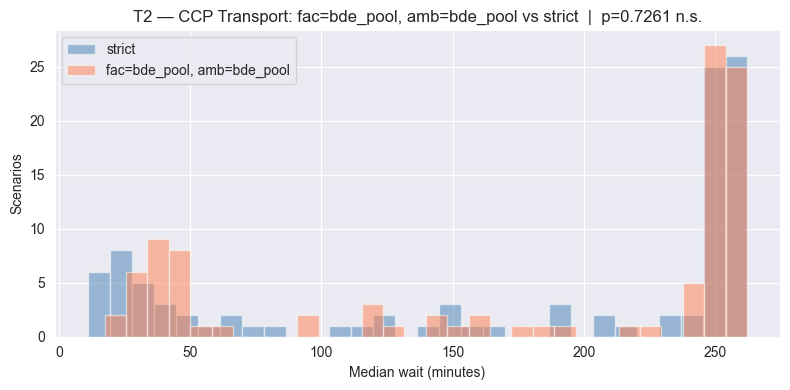

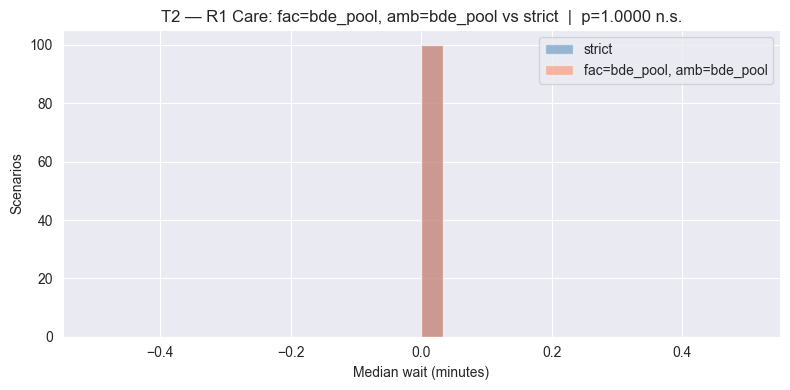

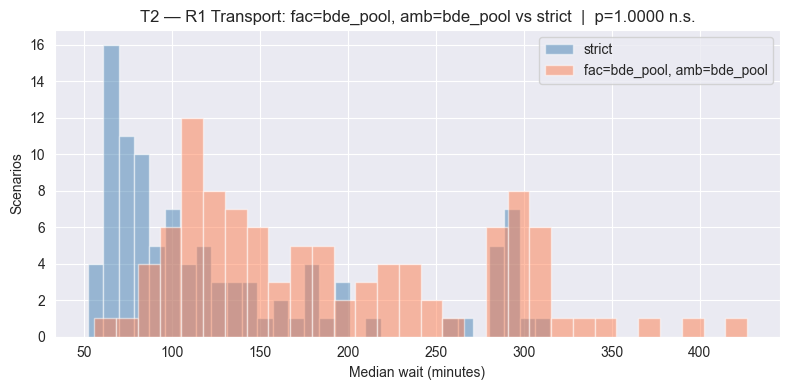

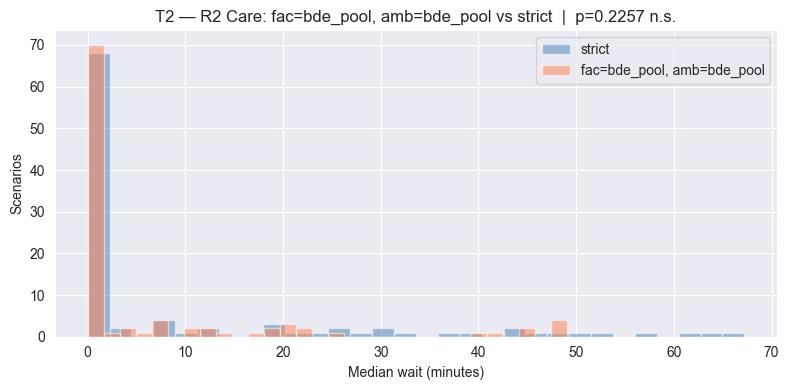

In [8]:
for fe, ae in POLICIES:
    plabel = f"fac={POLICY_LABELS[fe]}, amb={POLICY_LABELS[ae]}"
    pol = df[(df["facility_eligibility"] == fe) & (df["ambulance_eligibility"] == ae)]
    for p, phlabel in zip(phases, phase_labels):
        col = f"median_wait_{p}_T2"
        s = strict[col].dropna()
        q = pol[col].dropna()
        t, pval = stats.mannwhitneyu(s, q, alternative="greater")

        fig, ax = plt.subplots(figsize=(8, 4))
        ax.hist(s, bins=30, alpha=0.5, label="strict", color="steelblue")
        ax.hist(q, bins=30, alpha=0.5, label=plabel, color="coral")
        ax.set_xlabel("Median wait (minutes)")
        ax.set_ylabel("Scenarios")
        sig = "***" if pval < 0.001 else "**" if pval < 0.01 else "*" if pval < 0.05 else "n.s."
        ax.set_title(f"T2 — {phlabel}: {plabel} vs strict  |  p={pval:.4f} {sig}")
        ax.legend()
        plt.tight_layout()
        plt.show()

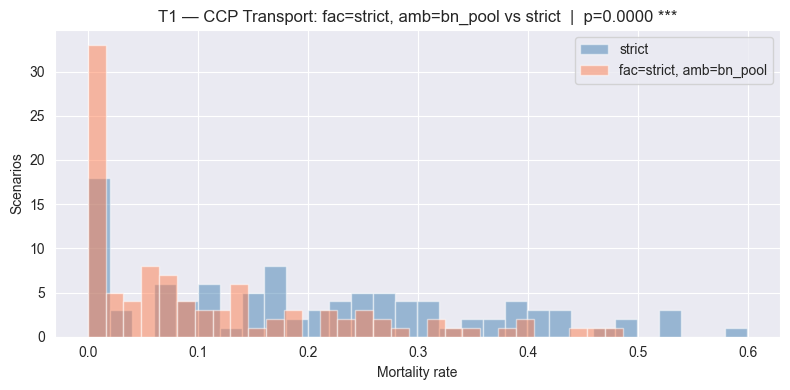

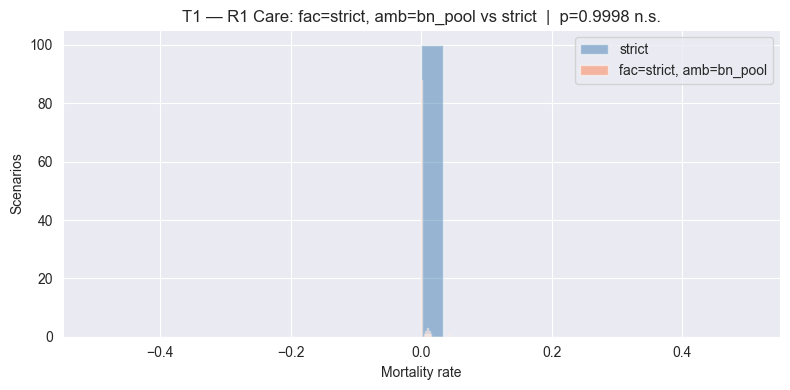

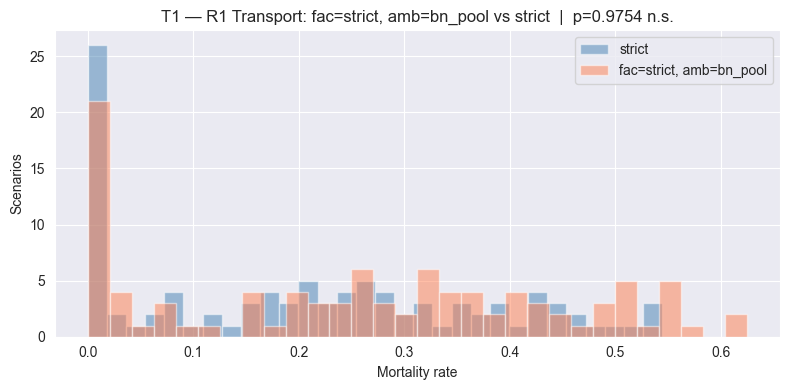

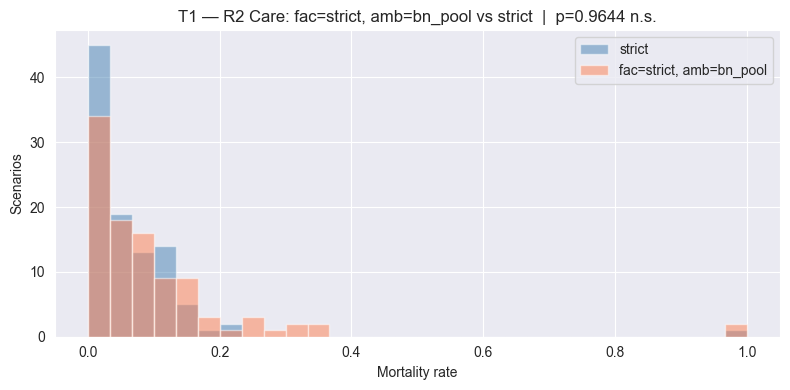

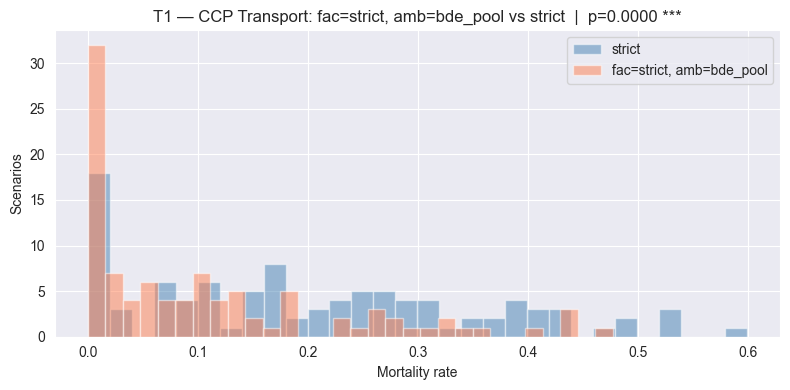

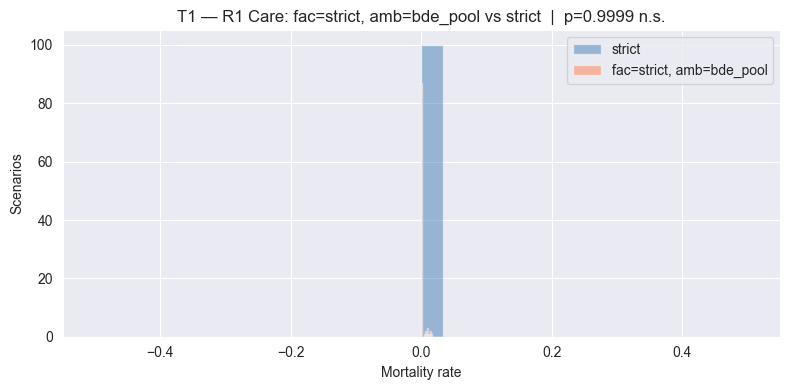

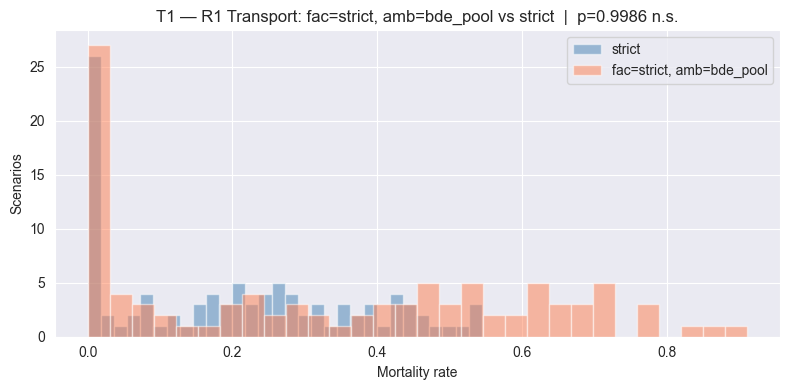

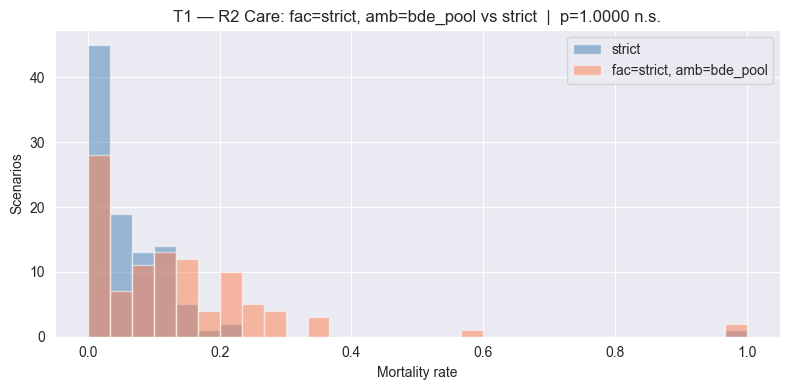

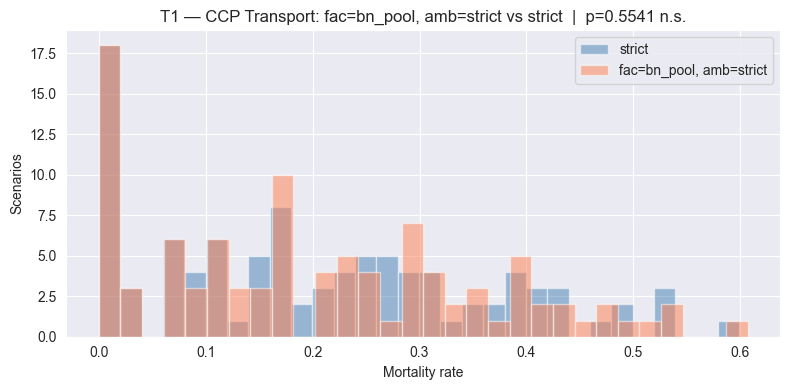

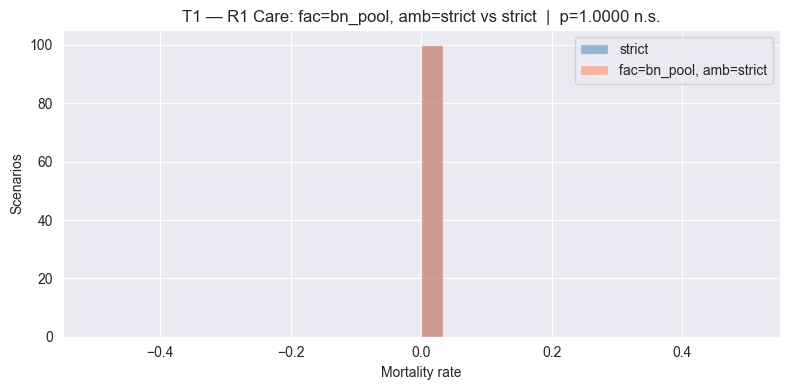

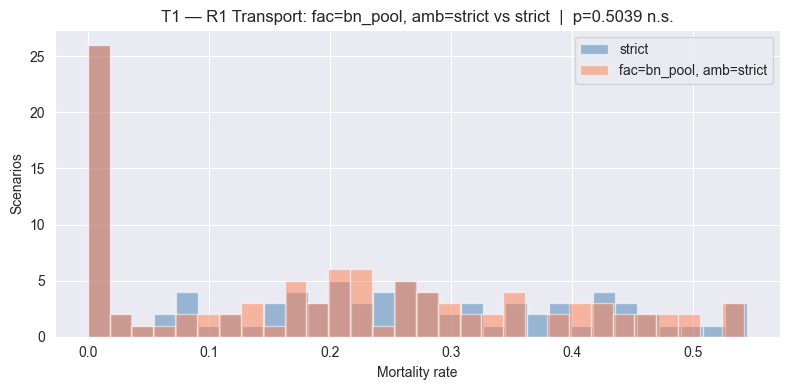

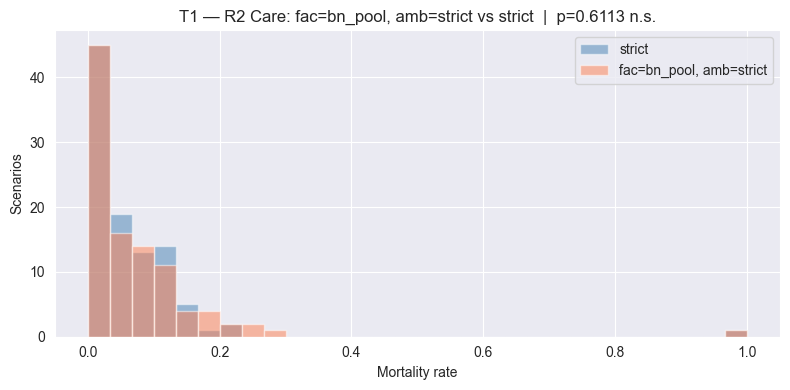

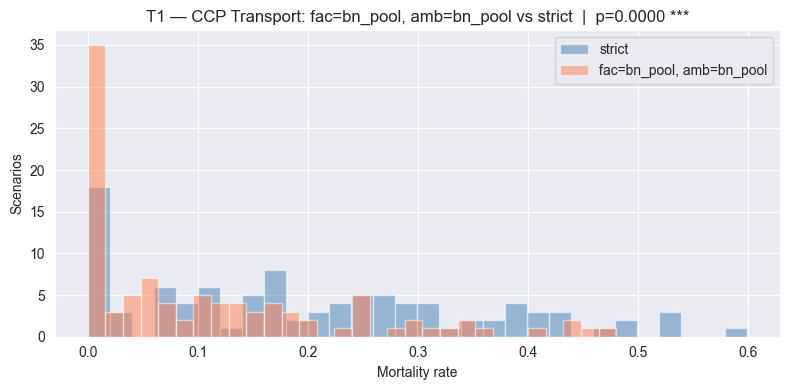

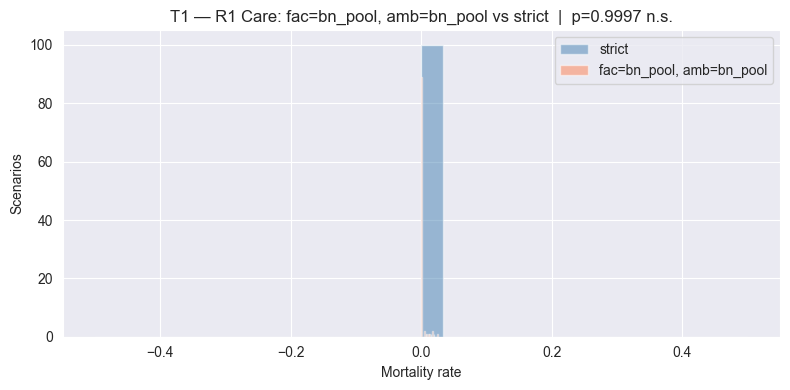

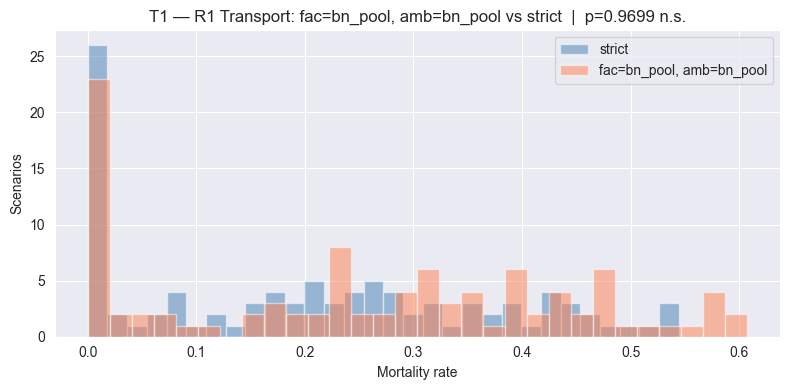

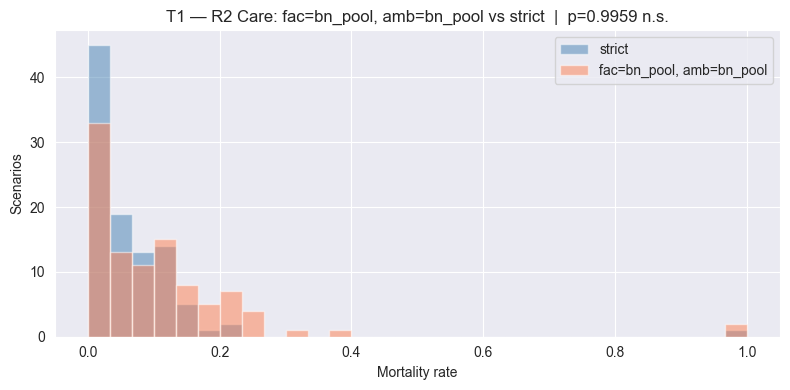

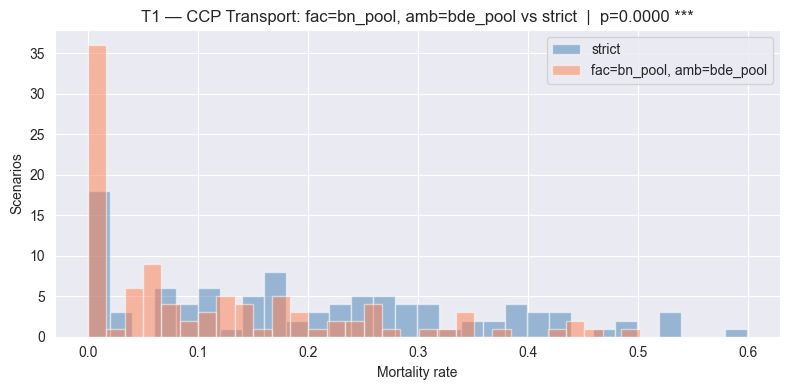

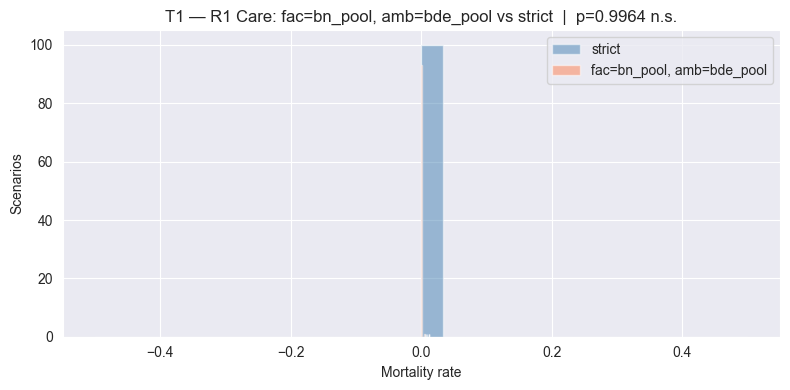

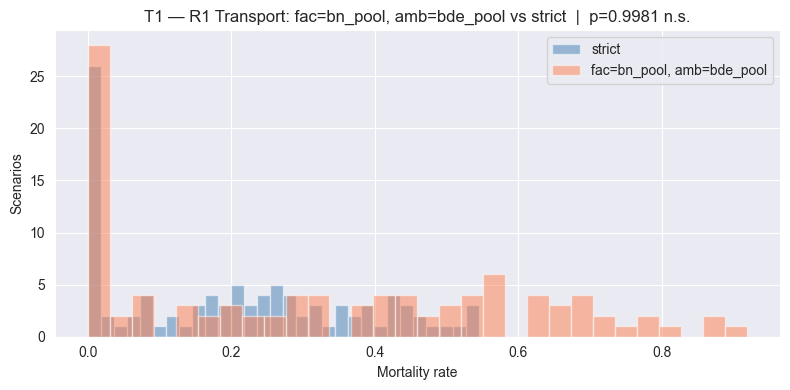

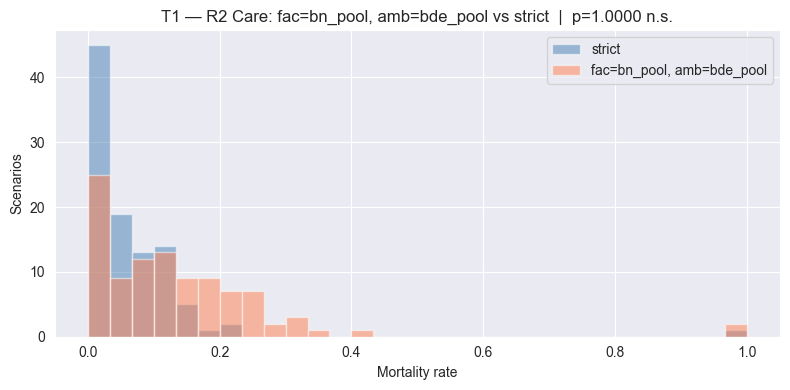

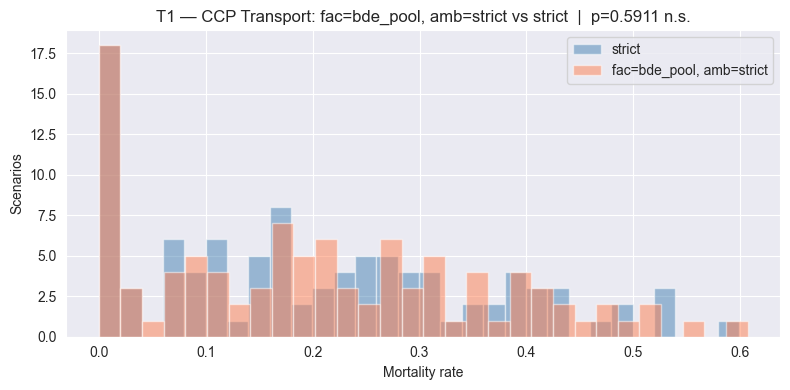

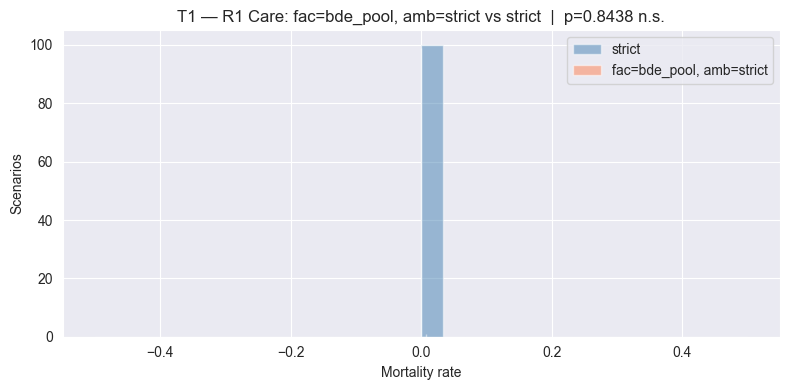

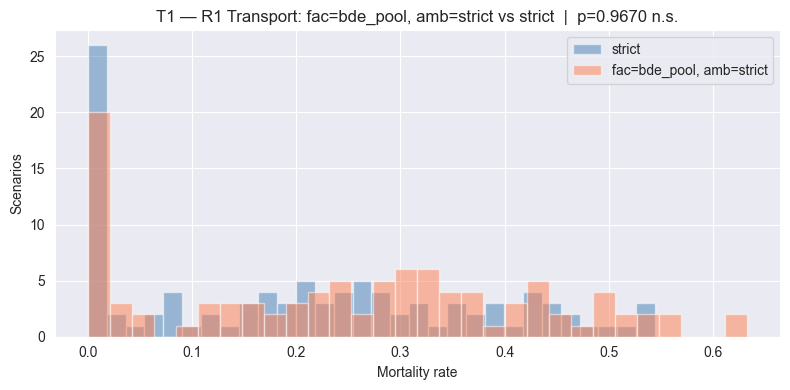

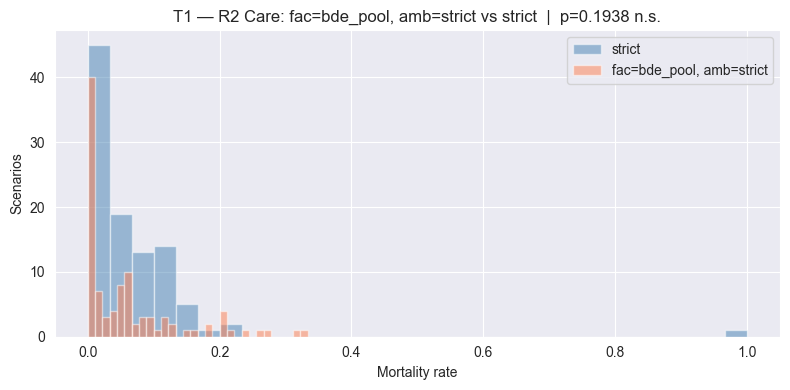

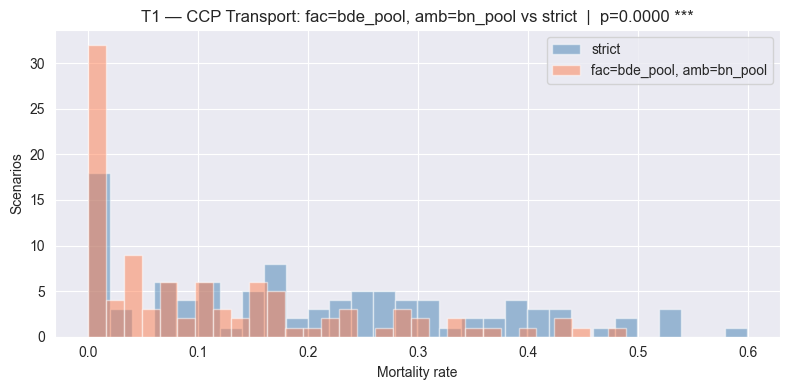

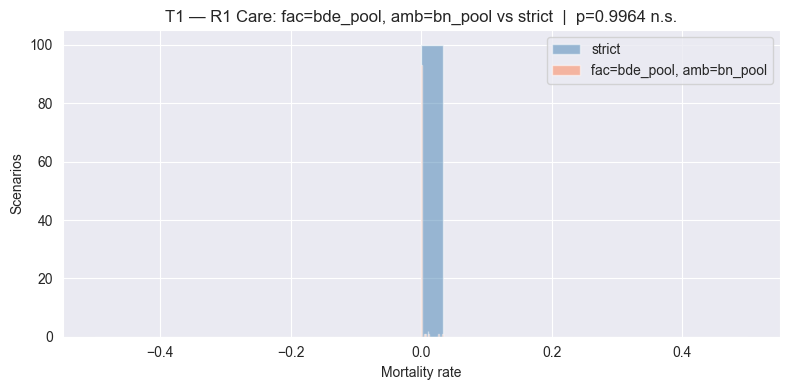

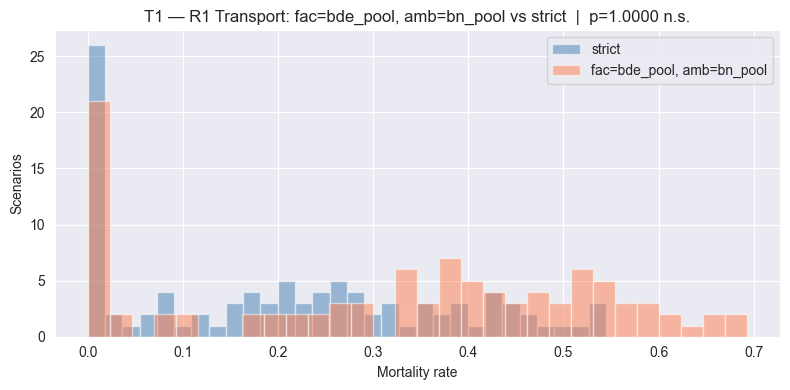

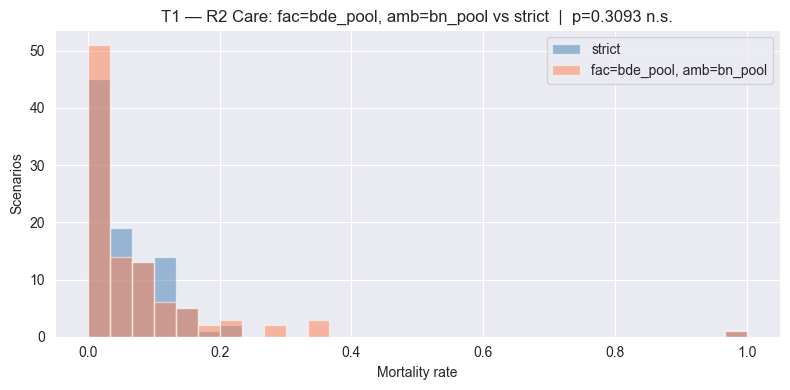

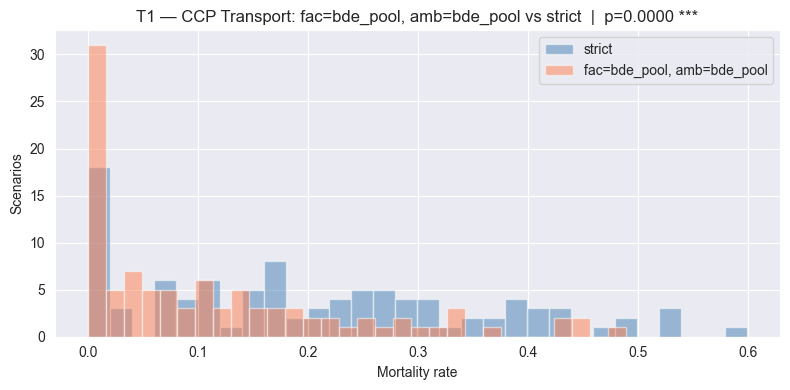

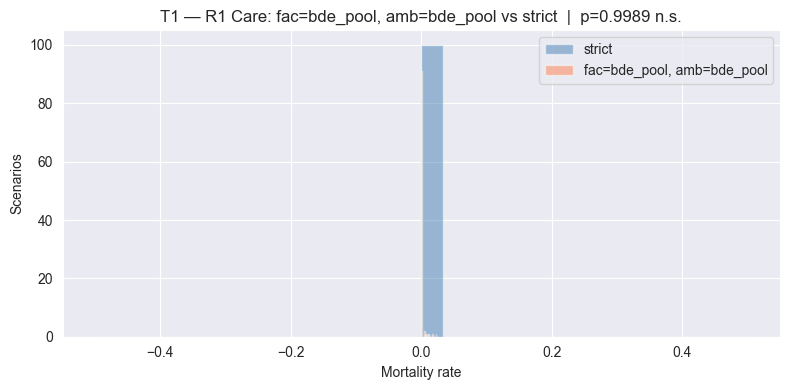

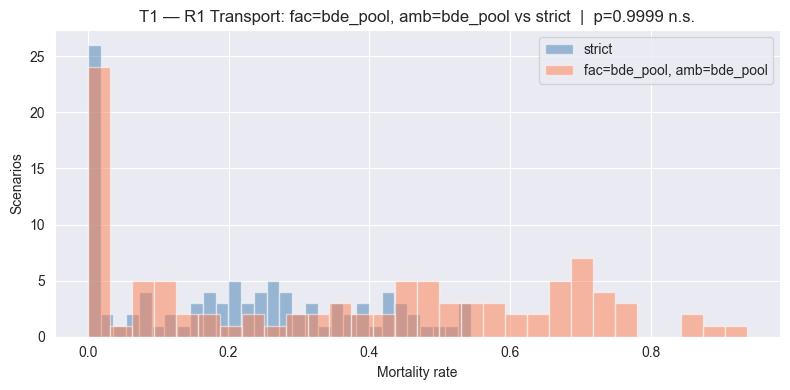

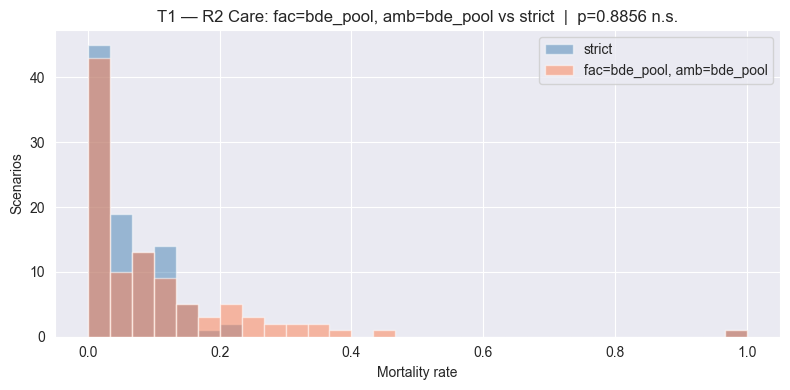

In [9]:
for fe, ae in POLICIES:
    plabel = f"fac={POLICY_LABELS[fe]}, amb={POLICY_LABELS[ae]}"
    pol = df[(df["facility_eligibility"] == fe) & (df["ambulance_eligibility"] == ae)]
    for p, phlabel in zip(phases, phase_labels):
        col = f"mortality_{p}_T1"
        s = strict[col].dropna()
        q = pol[col].dropna()
        t, pval = stats.mannwhitneyu(s, q, alternative="greater")

        fig, ax = plt.subplots(figsize=(8, 4))
        ax.hist(s, bins=30, alpha=0.5, label="strict", color="steelblue")
        ax.hist(q, bins=30, alpha=0.5, label=plabel, color="coral")
        ax.set_xlabel("Mortality rate")
        ax.set_ylabel("Scenarios")
        sig = "***" if pval < 0.001 else "**" if pval < 0.01 else "*" if pval < 0.05 else "n.s."
        ax.set_title(f"T1 — {phlabel}: {plabel} vs strict  |  p={pval:.4f} {sig}")
        ax.legend()
        plt.tight_layout()
        plt.show()

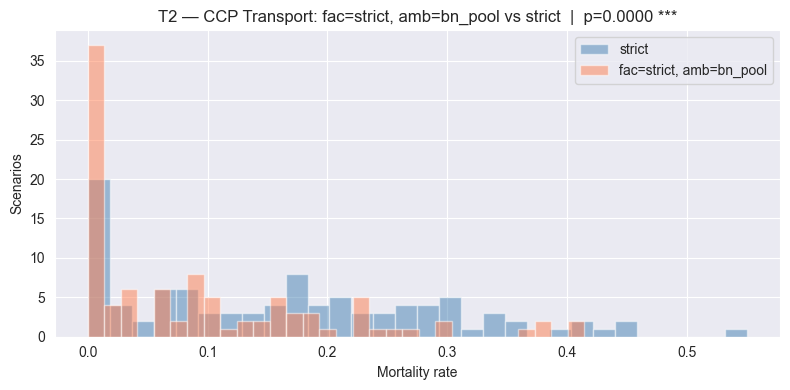

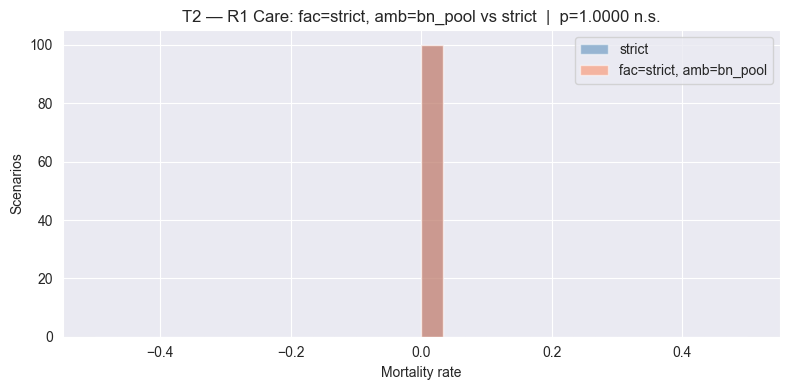

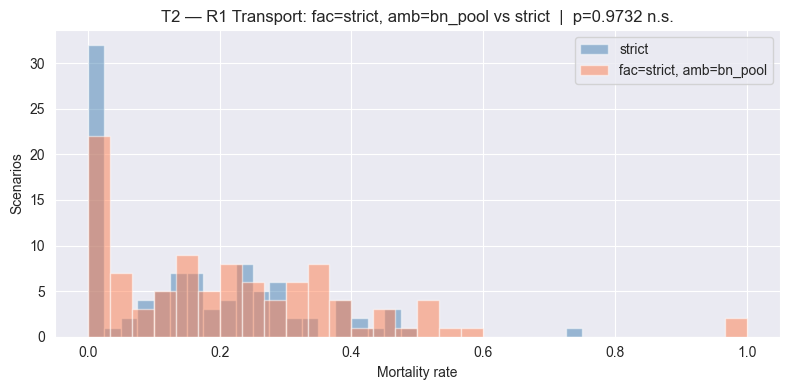

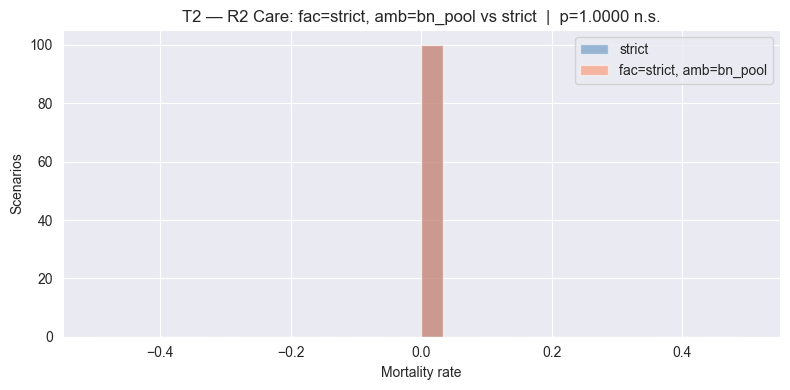

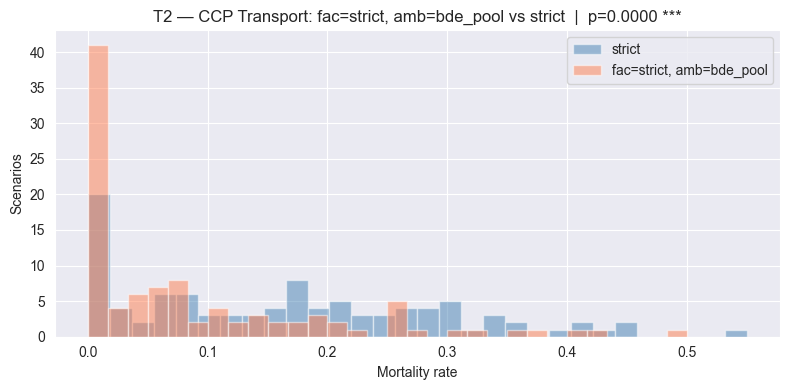

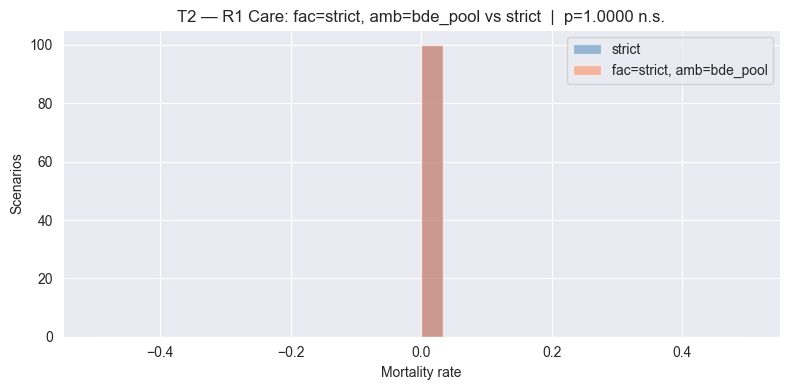

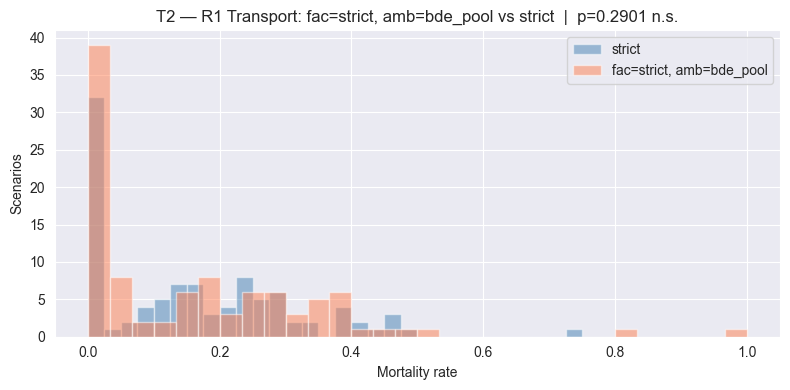

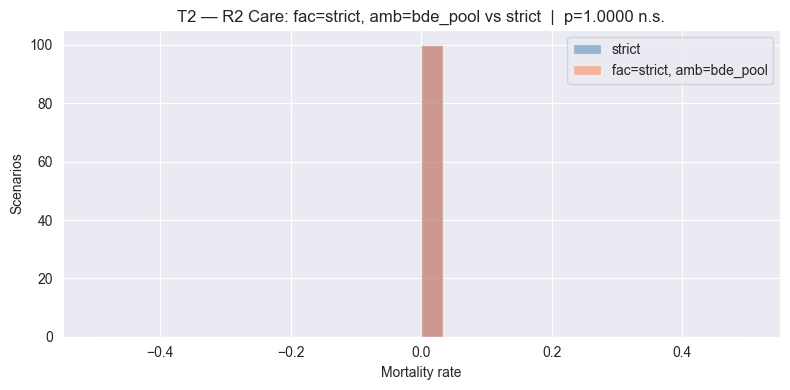

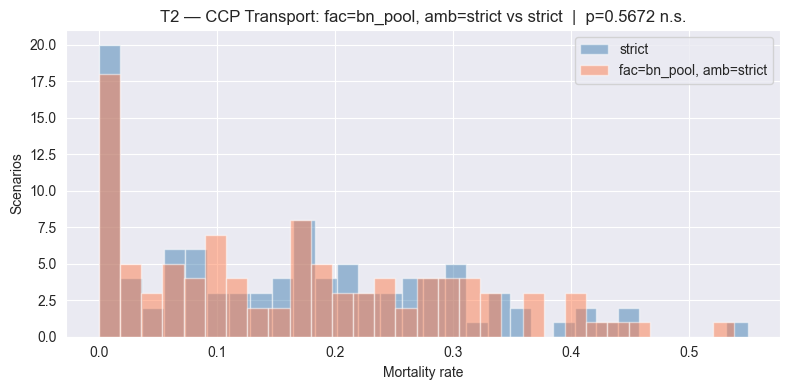

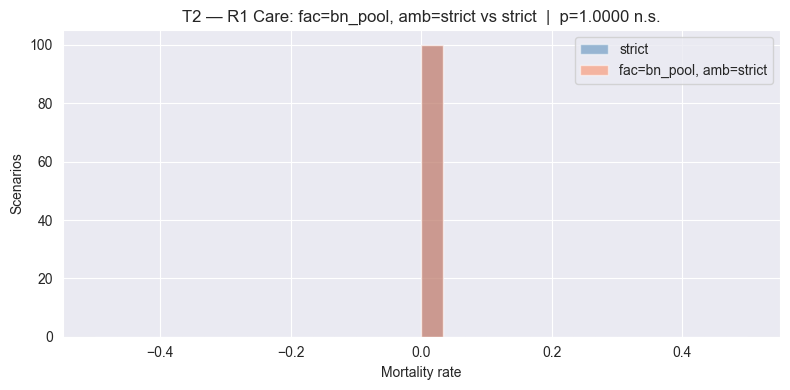

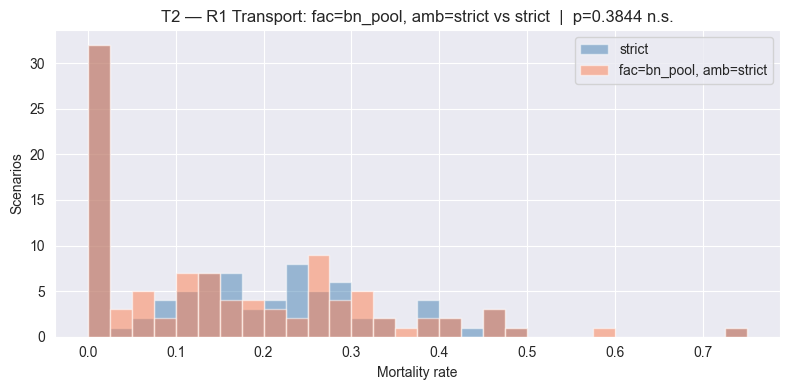

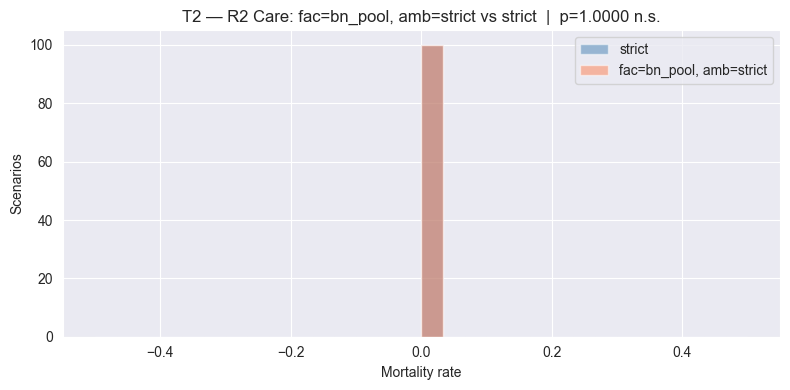

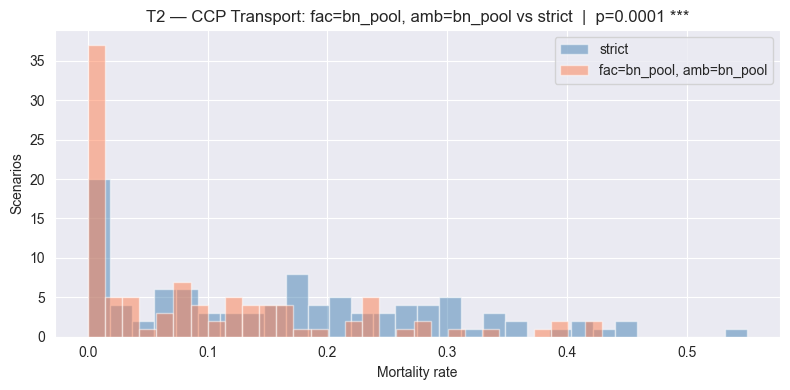

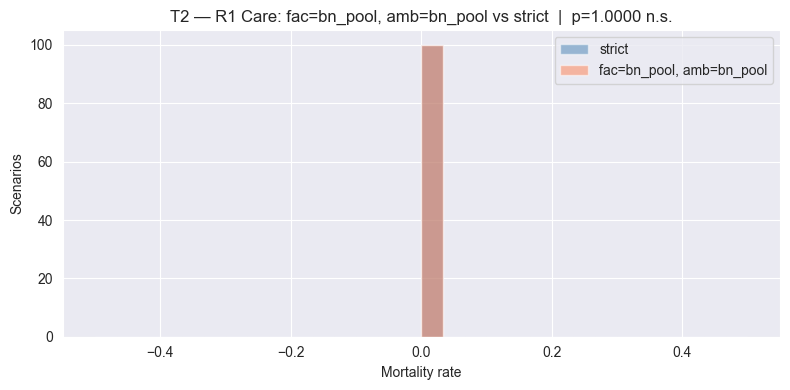

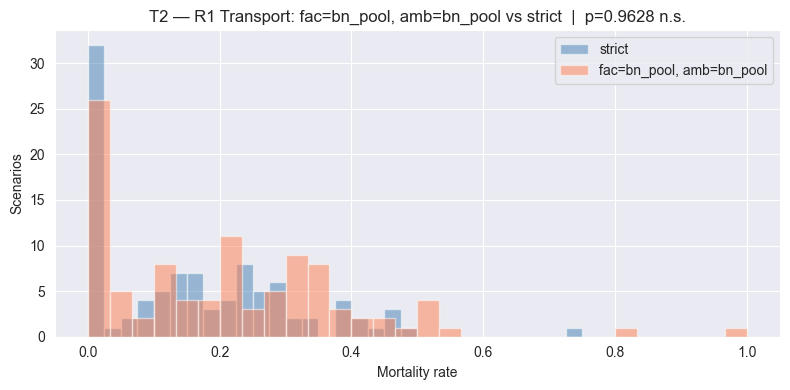

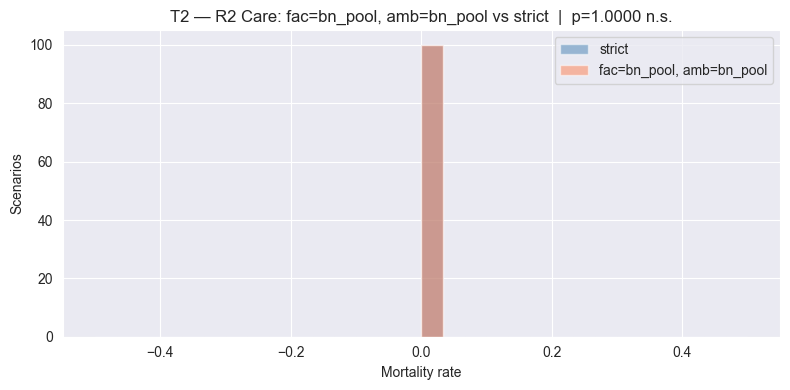

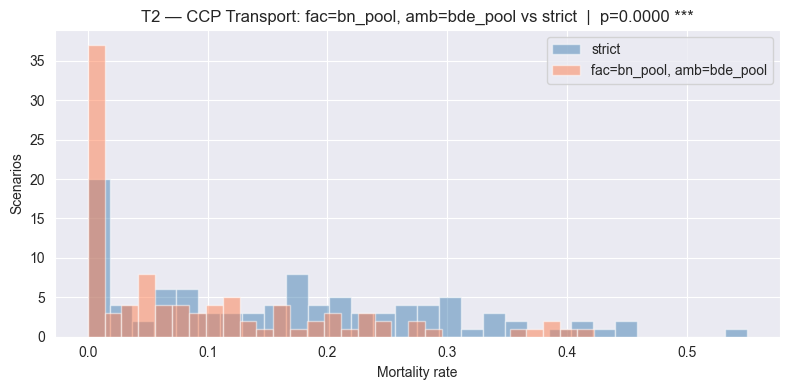

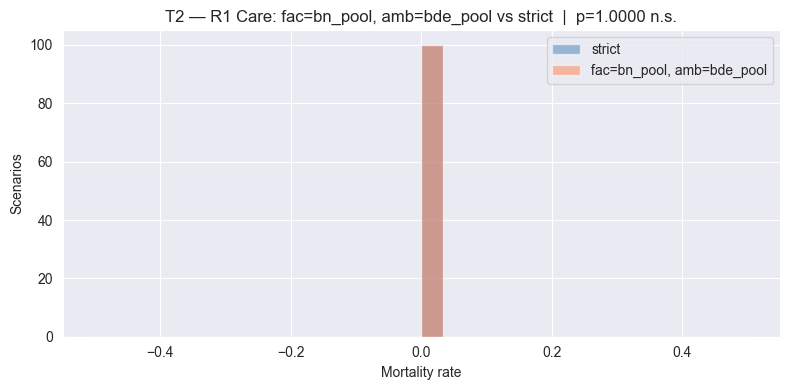

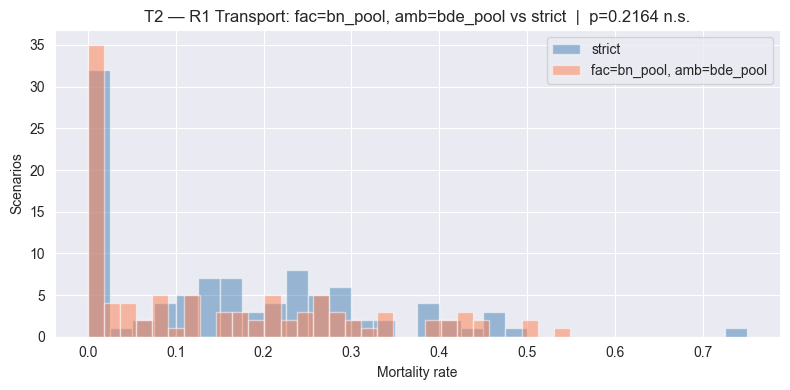

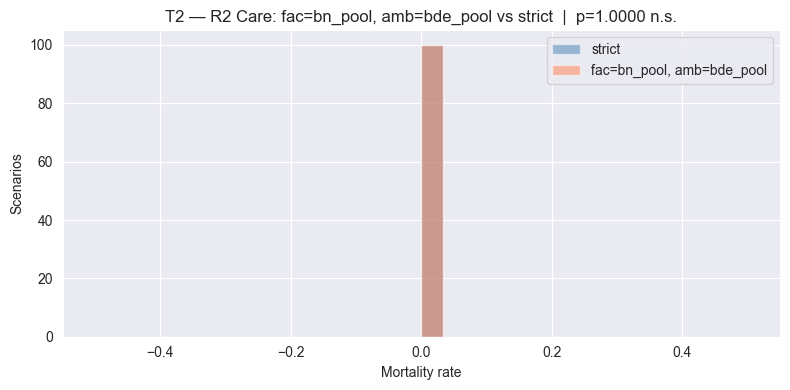

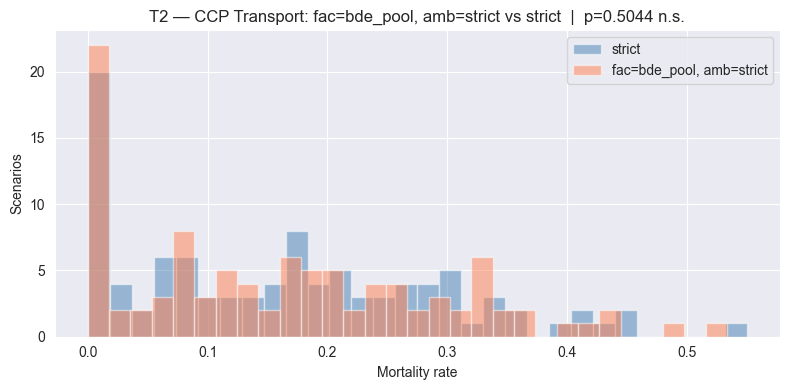

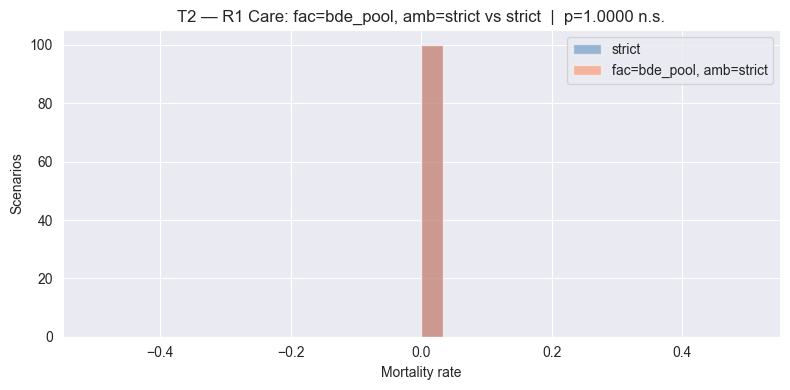

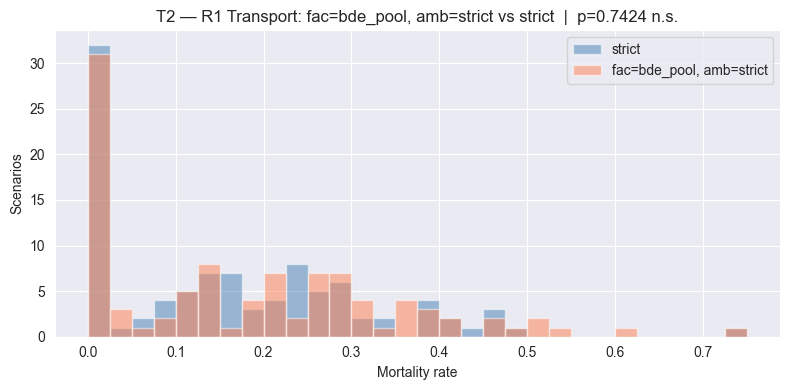

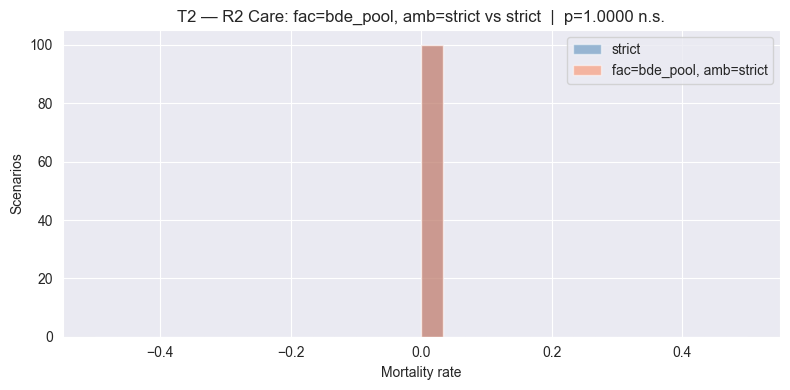

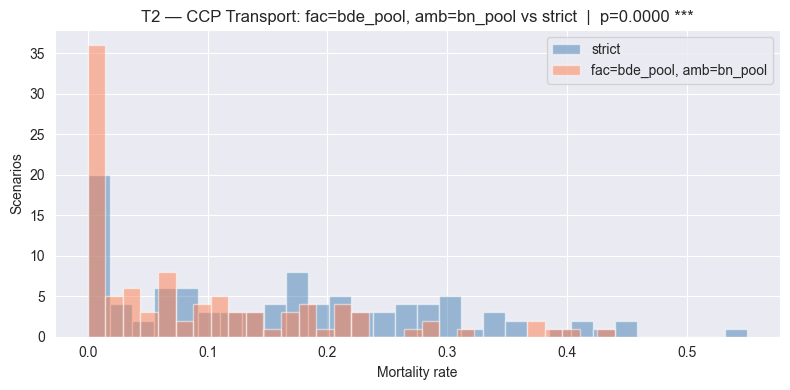

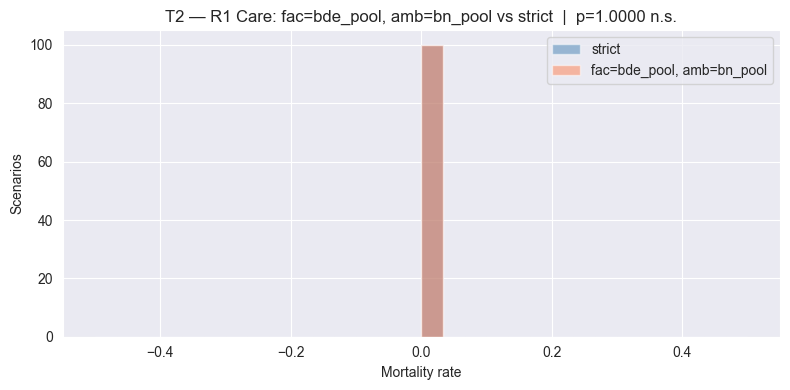

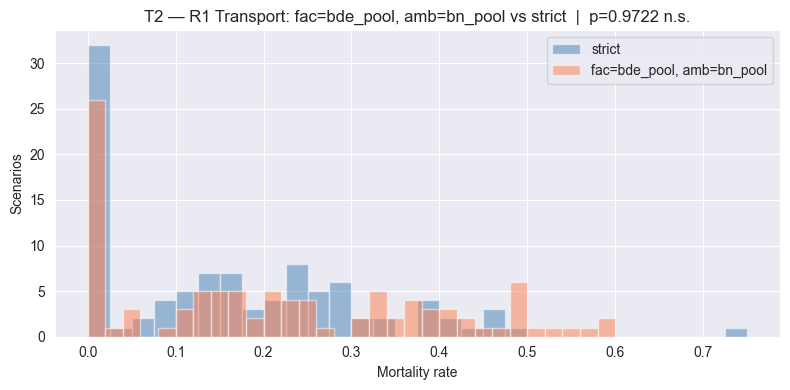

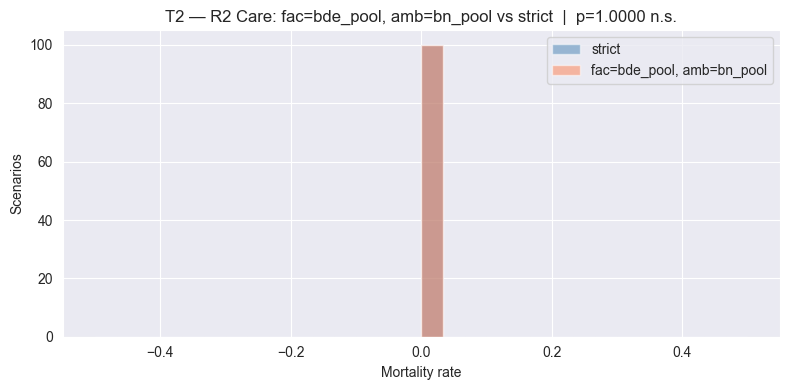

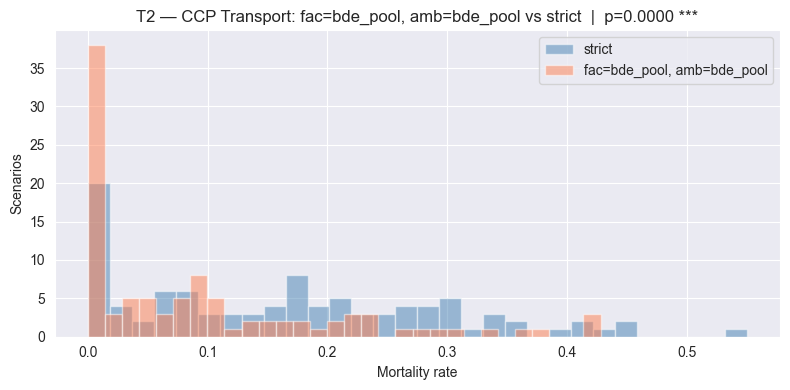

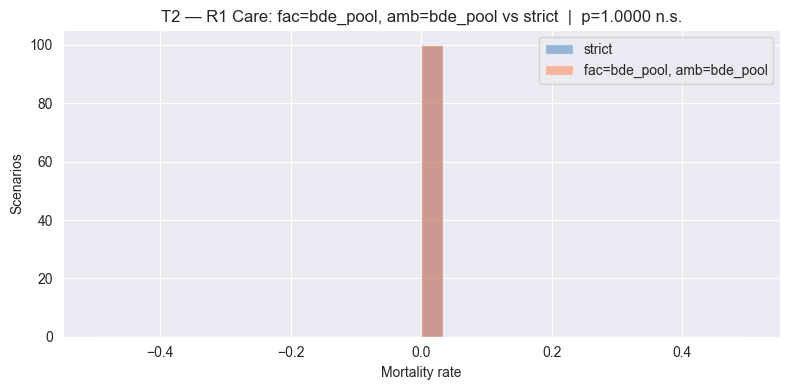

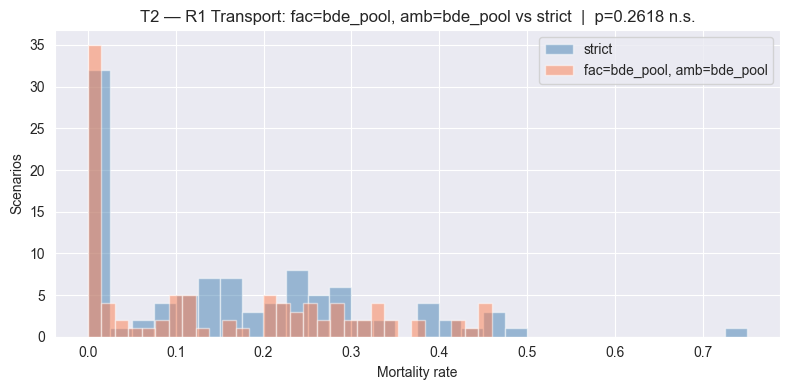

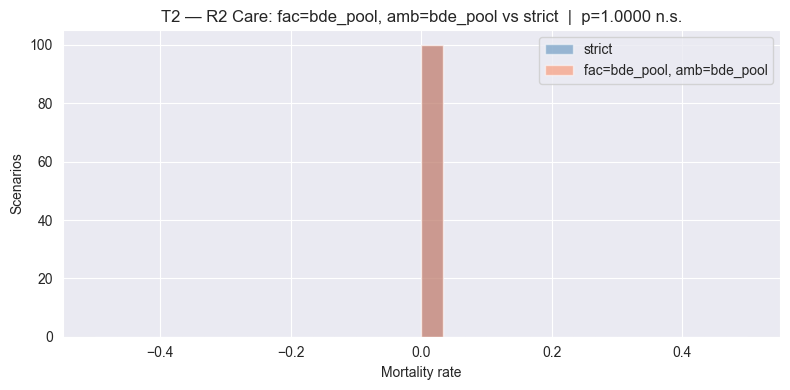

In [10]:
for fe, ae in POLICIES:
    plabel = f"fac={POLICY_LABELS[fe]}, amb={POLICY_LABELS[ae]}"
    pol = df[(df["facility_eligibility"] == fe) & (df["ambulance_eligibility"] == ae)]
    for p, phlabel in zip(phases, phase_labels):
        col = f"mortality_{p}_T2"
        s = strict[col].dropna()
        q = pol[col].dropna()
        t, pval = stats.mannwhitneyu(s, q, alternative="greater")

        fig, ax = plt.subplots(figsize=(8, 4))
        ax.hist(s, bins=30, alpha=0.5, label="strict", color="steelblue")
        ax.hist(q, bins=30, alpha=0.5, label=plabel, color="coral")
        ax.set_xlabel("Mortality rate")
        ax.set_ylabel("Scenarios")
        sig = "***" if pval < 0.001 else "**" if pval < 0.01 else "*" if pval < 0.05 else "n.s."
        ax.set_title(f"T2 — {phlabel}: {plabel} vs strict  |  p={pval:.4f} {sig}")
        ax.legend()
        plt.tight_layout()
        plt.show()

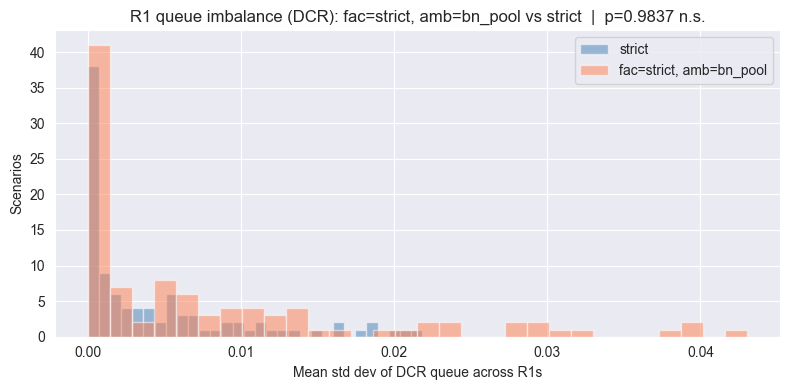

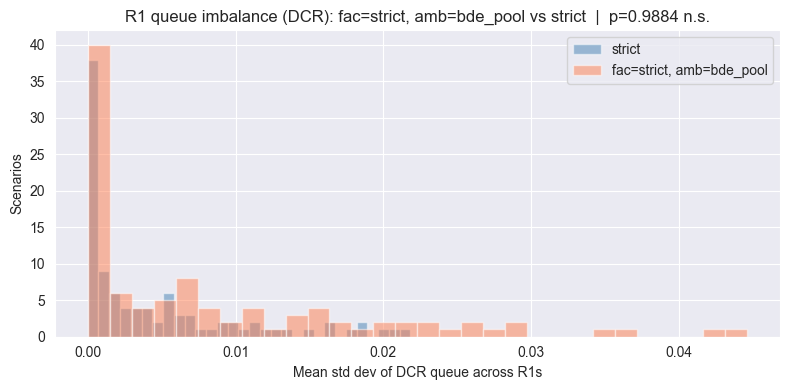

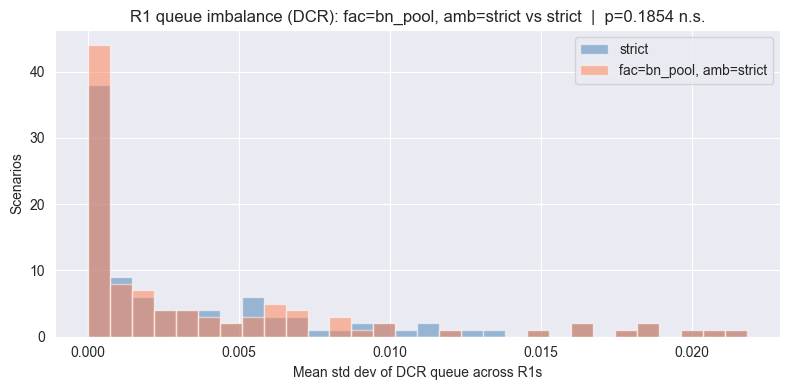

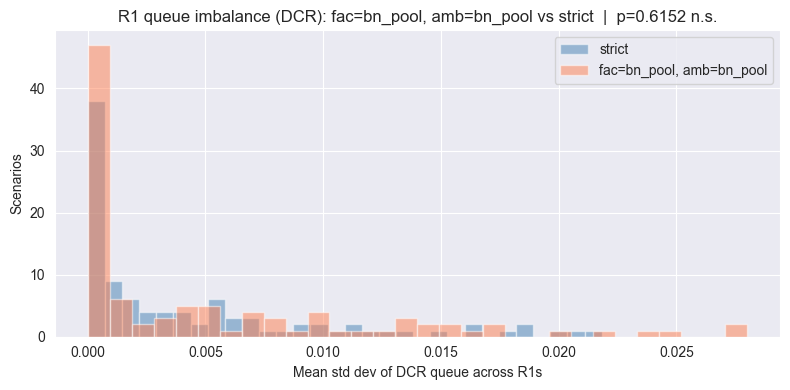

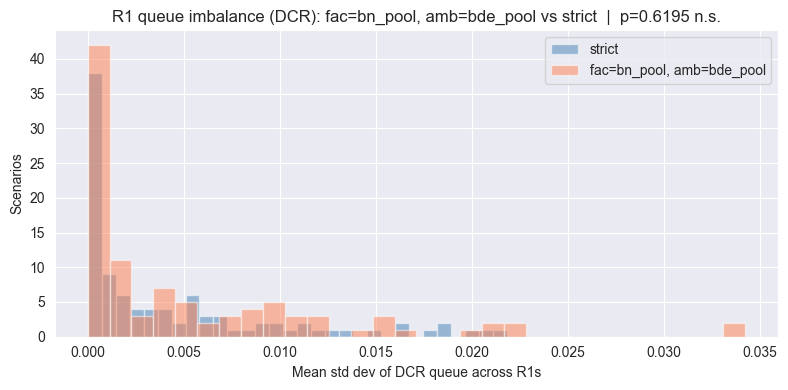

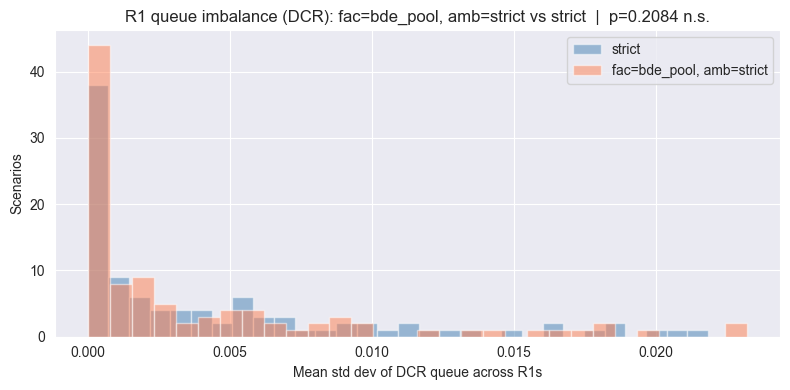

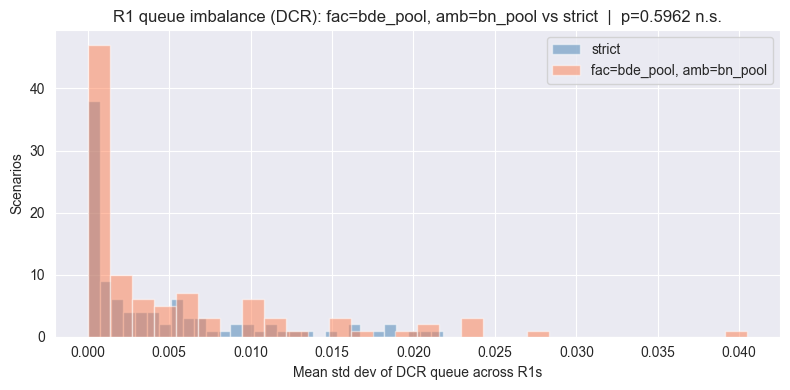

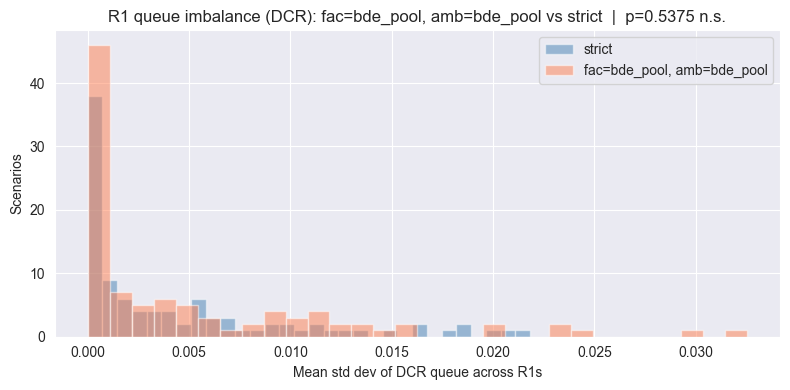

In [12]:
POLICIES = [
    (fe, ae)
    for fe in sorted(df["facility_eligibility"].unique())
    for ae in sorted(df["ambulance_eligibility"].unique())
    if not (fe == 0 and ae == 0)
]

for fe, ae in POLICIES:
    plabel = f"fac={POLICY_LABELS[fe]}, amb={POLICY_LABELS[ae]}"
    pol = df[(df["facility_eligibility"] == fe) & (df["ambulance_eligibility"] == ae)]

    col = "mean_std_queue_dcr"
    s = strict[col].dropna()
    q = pol[col].dropna()
    t, pval = stats.mannwhitneyu(s, q, alternative="greater")
    sig = "***" if pval < 0.001 else "**" if pval < 0.01 else "*" if pval < 0.05 else "n.s."

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(s, bins=30, alpha=0.5, label="strict", color="steelblue")
    ax.hist(q, bins=30, alpha=0.5, label=plabel, color="coral")
    ax.set_xlabel("Mean std dev of DCR queue across R1s")
    ax.set_ylabel("Scenarios")
    ax.set_title(f"R1 queue imbalance (DCR): {plabel} vs strict  |  p={pval:.4f} {sig}")
    ax.legend()
    plt.tight_layout()
    plt.show()

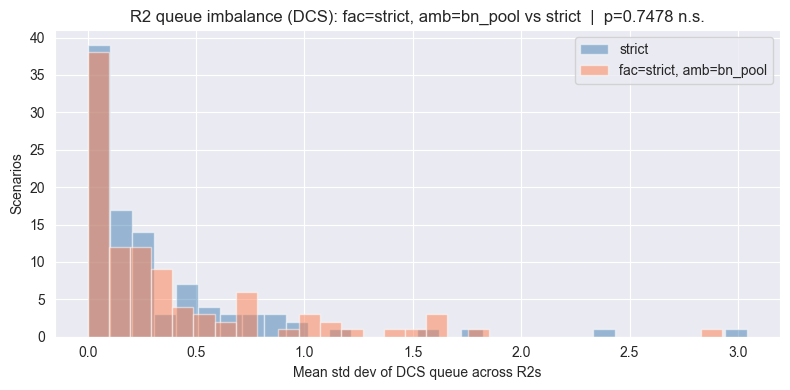

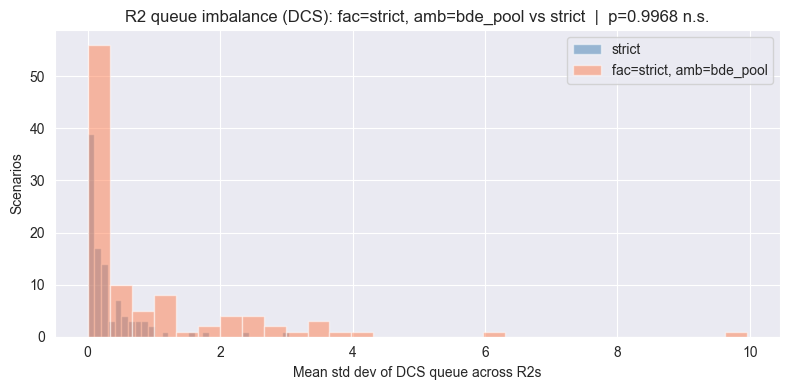

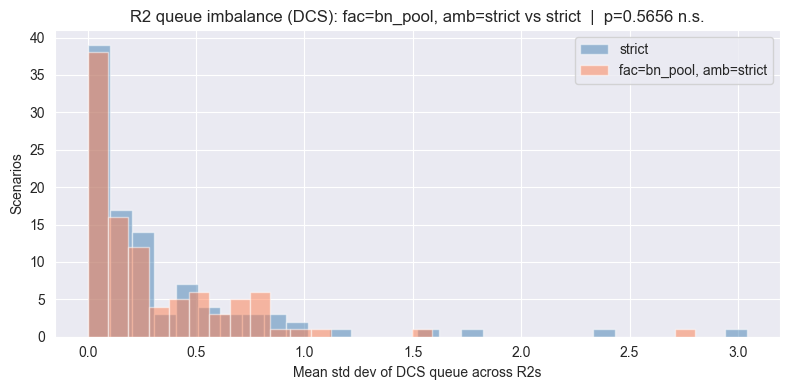

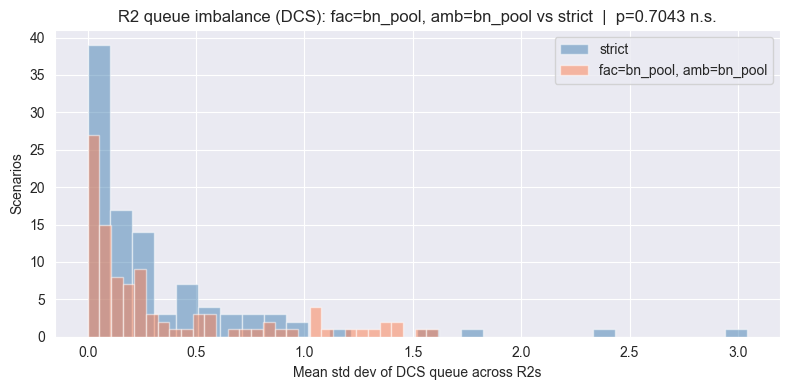

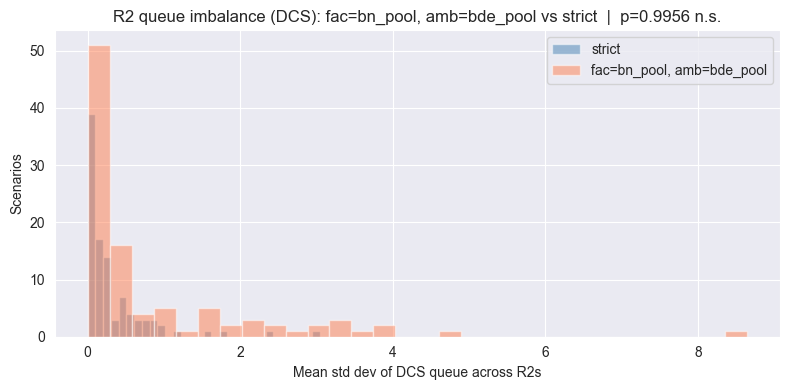

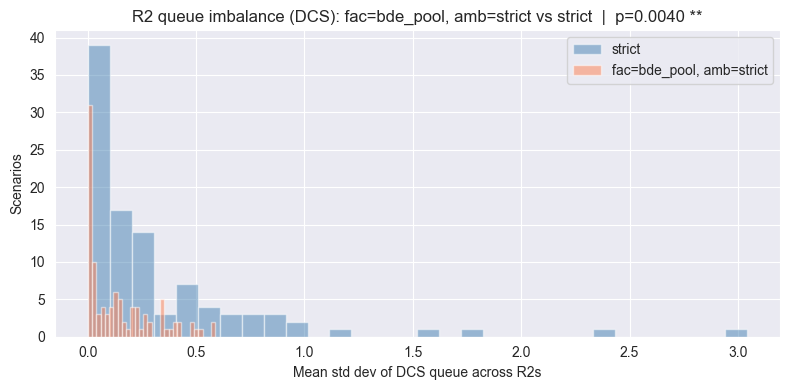

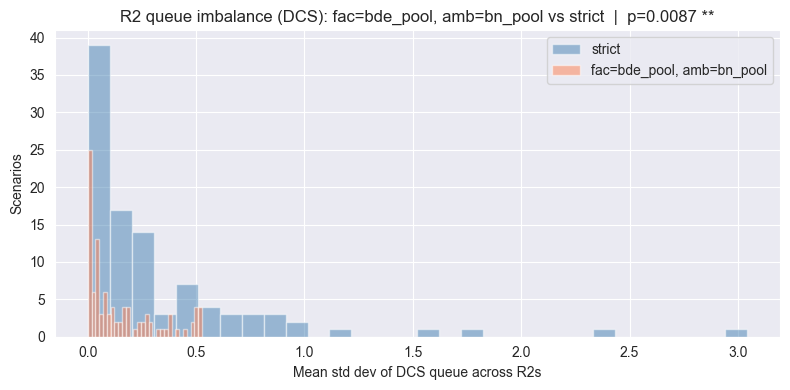

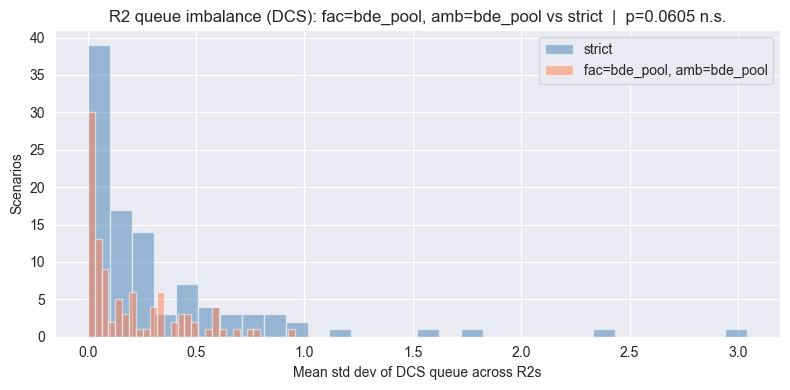

In [13]:
for fe, ae in POLICIES:
    plabel = f"fac={POLICY_LABELS[fe]}, amb={POLICY_LABELS[ae]}"
    pol = df[(df["facility_eligibility"] == fe) & (df["ambulance_eligibility"] == ae)]

    col = "mean_std_queue_dcs"
    s = strict[col].dropna()
    q = pol[col].dropna()
    t, pval = stats.mannwhitneyu(s, q, alternative="greater")
    sig = "***" if pval < 0.001 else "**" if pval < 0.01 else "*" if pval < 0.05 else "n.s."

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(s, bins=30, alpha=0.5, label="strict", color="steelblue")
    ax.hist(q, bins=30, alpha=0.5, label=plabel, color="coral")
    ax.set_xlabel("Mean std dev of DCS queue across R2s")
    ax.set_ylabel("Scenarios")
    ax.set_title(f"R2 queue imbalance (DCS): {plabel} vs strict  |  p={pval:.4f} {sig}")
    ax.legend()
    plt.tight_layout()
    plt.show()